# How People Prompt AI Image Generators
### An Analysis of Real-World Text-to-Image Prompts (DiffusionDB)

**Course:** Python for Data Analysis - Final Project
**Students:** Tugba Irem Demirci, Ayse Sule Ekiz

---

**Contents**
1. Project Introduction
2. Loading the Dataset
3. Understanding the Dataset
4. Data Cleaning
5. Exploratory Data Analysis Using Pandas
6. Data Visualization
7. Interpretation of Results
8. Answers to the Research Questions
9. Limitations
10. Conclusion
11. References

## Section 1 - Project Introduction

**Project title:** How People Prompt AI Image Generators: An Analysis of Real-World Text-to-Image Prompts

**Dataset name:** DiffusionDB (2M subset, metadata table)

**Dataset source:** Polo Club of Data Science, Georgia Institute of Technology (hosted on Hugging Face and GitHub)

**Dataset link:** https://huggingface.co/datasets/poloclub/diffusiondb

### Brief description of the dataset
DiffusionDB is a large-scale dataset of text prompts written by real users of the **Stable Diffusion** image generator.
The prompts were collected from the official Stable Diffusion Discord server in August 2022.
Its metadata table has **2,000,000 rows and 13 columns**. Each row is one generated image. The columns are:

| Column | Meaning |
|---|---|
| `image_name` | Unique file name of the generated image |
| `prompt` | The text prompt the user typed |
| `part_id` | Which part (zip file) of the dataset the image belongs to |
| `seed` | Random seed used for the generation |
| `step` | Number of denoising steps (more steps = slower, often more detail) |
| `cfg` | Guidance scale: how strictly the model follows the prompt |
| `sampler` | Sampling algorithm, stored as a number code (1-9) |
| `width`, `height` | Image size in pixels |
| `user_name` | Anonymized (SHA-256 hashed) Discord user ID |
| `timestamp` | When the image was generated (UTC) |
| `image_nsfw` | Likelihood that the image is NSFW (0-1; **2.0 = already blurred by Stable Diffusion**) |
| `prompt_nsfw` | Likelihood that the prompt text is toxic or sexual (0-1) |

We analyze a **sample of about 100,000 rows** of the metadata table. This keeps the project manageable in Pandas while preserving real-world variety.
The sample was built with the script `make_sample.py` (included in the repository):
we randomly chose **500 users and kept all of their generations**, instead of choosing random single rows.
We did this because Research Question 2 looks at how a person changes their prompts *during a session*; a row-level sample would cut those sessions into disconnected pieces.
Rows without a usable user ID were sampled at a 5% rate so that the sample keeps the same data-quality problems as the full table.

### Why we selected this dataset
Generative AI is quickly changing how people create images, but little is known about how everyday users express their creative intentions to these tools.
We are interested in how people collaborate with AI in creative work, and one of us brings a background in design and studio art alongside computer science.
This dataset lets us study that behavior using real user data rather than assumptions.
It also requires genuine cleaning work, such as decoding sampler codes, handling duplicate generations, standardizing prompt text, and filtering content flagged as NSFW.

### Research questions
1. **Q1 - Styles and artists:** Which artistic styles, mediums, and artist names appear most often in prompts, and how concentrated is their use among a small number of popular terms?
2. **Q2 - Prompt revision:** How do users revise their prompts within a session? For example, do prompts become longer or more style-specific over repeated generations by the same user?
3. **Q3 - Generation settings:** How are generation settings such as guidance scale, step count, and image size distributed, and do they relate to prompt length or complexity?

## Section 2 - Loading the Dataset

We import the libraries used in the project and load the sample with Pandas.

The data is stored as a **Parquet** file (the format the original dataset is published in) instead of CSV, because:
- prompts contain commas, quotes and line breaks, which make CSV files easy to break;
- Parquet keeps the correct data types (for example, `timestamp` is loaded directly as a date-time);
- the file is much smaller (about 16 MB instead of about 40 MB as CSV), so it fits in the GitHub repository.

`pd.read_parquet()` works exactly like `pd.read_csv()`, it just reads a different file format (it needs the `pyarrow` package).

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings so wide tables and long prompts are readable
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = "data/diffusiondb_sample.parquet"

df_raw = pd.read_parquet(DATA_PATH)   # original sample, never modified
df = df_raw.copy()                    # working copy that we will clean

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 110,698 rows and 13 columns


## Section 3 - Understanding the Dataset

Before analyzing anything, we inspect the structure, the data types and the value ranges of every column.

### 3.1 Size and columns

In [3]:
print("Shape (rows, columns):", df.shape)
print()
print("Columns:", df.columns.tolist())

Shape (rows, columns): (110698, 13)

Columns: ['image_name', 'prompt', 'part_id', 'seed', 'step', 'cfg', 'sampler', 'width', 'height', 'user_name', 'timestamp', 'image_nsfw', 'prompt_nsfw']


### 3.2 First and last rows

In [4]:
df.head()

,image_name,prompt,part_id,seed,step,cfg,sampler,width,height,user_name,timestamp,image_nsfw,prompt_nsfw
0,aa8b7c67-13fe-4188-97d7-3745a4f99797.png,"1 9 4 0's classic concept car from cyberpunk 2 0 7 7. art by jesper ejsing, feng zhu, ...",1664,2089247963,50,7.000,8,832,512,696d842c8c17a345b74c61288ef393f74fe8cf4236727d25b75acc3913c07d07,2022-08-20 12:27:00+00:00,0.243,0.001
1,20b2e116-96b8-407d-9cf9-b666f3a30e59.png,"portrait of an aesthetic punk goth guy with long dreads, inspired by lisa frank, inspi...",345,1822521859,50,7.000,8,512,768,3513f0427e632ececa214084b2fddc9410b44dd21269e777130e86278653c4d9,2022-08-20 04:58:00+00:00,0.236,0.021
2,3a5cdf30-74ef-4215-9451-96a233912e55.png,"trail cam footage of lana del rey, photorealistic, horror",127,2941256703,150,7.000,8,512,512,0defe58f5ce30f10ab1e8bfabcb1b655e324f4b032065b14c5b3b84a41c83742,2022-08-09 03:27:00+00:00,0.165,0.007
3,4ce1decc-4c61-495e-8a70-334a239a2938.png,"stunning beautiful woman, sitting in beach, 50mm",668,259038050,50,7.000,8,512,512,7f9fb94c16d00ad62a4a884ca29ca3e654a150fe8c4e0e3a6181db522fa91b92,2022-08-09 04:42:00+00:00,0.866,0.002
4,a5153d51-c292-462f-96bb-68c3bb9c320c.png,"fighter jet from the 5 0 s beautiful clouds in the background, grainy footage, black a...",885,3076663381,50,7.000,8,512,512,66d876c971f3f01f62dfa9a9fcf16c6f979430261e00e52bb15f36aa87fce28c,2022-08-11 20:18:00+00:00,0.031,0.013


In [5]:
df.tail()

,image_name,prompt,part_id,seed,step,cfg,sampler,width,height,user_name,timestamp,image_nsfw,prompt_nsfw
110693,8669bffd-ae11-45d4-88ff-00ec33acfb44.png,"hyperdetailed full body portrait of a knight, hyperdetailed black fancy armor, hyperde...",1444,264870918,50,7.000,8,512,640,a68d936b350d441cb4cee423250003f490d4cc7e26938741318c8254dc3c29d0,2022-08-17 17:35:00+00:00,0.239,0.006
110694,939784fe-bc00-4381-ab9c-200da88d177c.png,"space fighter cyborg man wearing a silly party hat, scifi warrior paladin, trending on...",1297,1213464703,50,7.000,8,512,512,deleted_acount,2022-08-12 20:44:00+00:00,0.094,0.468
110695,46eca5ae-6f3c-44ef-9c0a-87eecfe51b4c.png,gallery. collection. curation. gallery of art. digital art. 4 k. hdr. masterpieces. cu...,1900,1924945558,50,7.000,8,1024,256,91bfd0b5d709502577898a676a5bb1aaf0fbebadee9d9f5105bab4ae1875d113,2022-08-12 04:54:00+00:00,0.083,0.000
110696,831accde-0484-4943-a2ea-393f57aae5d3.png,"eric carle illustration of a capybara, high quality, ultra detailed",24,2275706728,50,7.000,8,512,512,78287b78c3431555ee1cf07bca01b5e3322536e708fb4831731236205baf673e,2022-08-13 03:09:00+00:00,0.097,0.001
110697,ba39c640-3d3c-4c19-a560-1eb062bd368a.png,"a tennis ball monster with halo, digital art, fantasy, magic, trending on artstation, ...",322,2989690879,50,7.000,8,512,512,0e5c74364b26e5f62d47ced8c91aa1fdb6c80c452807ff051490c4da691fa6e4,2022-08-08 19:18:00+00:00,0.120,0.011


### 3.3 Data types and non-null counts

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110698 entries, 0 to 110697
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype              
---  ------       --------------   -----              
 0   image_name   110698 non-null  str                
 1   prompt       110698 non-null  str                
 2   part_id      110698 non-null  uint16             
 3   seed         110698 non-null  uint32             
 4   step         110698 non-null  uint16             
 5   cfg          110693 non-null  float32            
 6   sampler      110698 non-null  uint8              
 7   width        110698 non-null  uint16             
 8   height       110698 non-null  uint16             
 9   user_name    110690 non-null  str                
 10  timestamp    110690 non-null  datetime64[us, UTC]
 11  image_nsfw   110698 non-null  float32            
 12  prompt_nsfw  110698 non-null  float32            
dtypes: datetime64[us, UTC](1), float32(3), str(3), uint16(4), uint32(1), u

### 3.4 Summary statistics of the numerical columns

In [7]:
df[["step", "cfg", "width", "height", "image_nsfw", "prompt_nsfw"]].describe()

,step,cfg,width,height,image_nsfw,prompt_nsfw
count,"110,698.000","110,693.000","110,698.000","110,698.000","110,698.000","110,698.000"
mean,61.273,8.414,604.124,589.471,0.184,0.025
std,30.731,"9,128,234.000",189.077,155.215,0.285,0.095
min,0.000,"-2,147,483,648.000",64.000,64.000,0.010,0.000
25%,50.000,7.000,512.000,512.000,0.065,0.001
50%,50.000,7.000,512.000,512.000,0.096,0.002
75%,50.000,7.000,640.000,704.000,0.161,0.007
max,150.000,"2,147,483,648.000","15,616.000","15,616.000",2.000,0.997


### 3.5 Text and categorical columns

In [8]:
# How many different values does each column have?
df.nunique().sort_values(ascending=False)

image_name     110698
image_nsfw     108224
seed           103493
prompt          81380
prompt_nsfw     81035
timestamp       19104
part_id          2000
user_name         501
cfg               220
step               73
width              33
height             31
sampler             9
dtype: int64

In [9]:
print("Time period covered:", df["timestamp"].min(), "to", df["timestamp"].max())
print()
print("Sampler codes (numbers, not names):")
print(df["sampler"].value_counts())

Time period covered: 2022-08-06 22:00:00+00:00 to 2022-08-20 13:33:00+00:00

Sampler codes (numbers, not names):
sampler
8    108940
4      1032
3       470
1        80
2        50
7        50
5        34
6        28
9        14
Name: count, dtype: int64


### 3.6 Missing values and first signs of problems

In [10]:
df.isnull().sum()

image_name     0
prompt         0
part_id        0
seed           0
step           0
cfg            5
sampler        0
width          0
height         0
user_name      8
timestamp      8
image_nsfw     0
prompt_nsfw    0
dtype: int64

In [11]:
# Users with the most rows - one "user" looks suspicious
df["user_name"].value_counts().head(5)

user_name
c23e4244a45610658beb6ef36424544447e3b17014afe7bb63b4ded6eebe9bf4    5535
db94325a7d7db2b6150489ad78e51fecd00b1086cb7cf949d17dd9df9f7717e7    3759
439e936e49621a885a3264ada39f93c78b9f1180c88b4616da4dcd53897c3899    3180
3db19c0f311420d61e8e9b8030aec1a00b3353b8f87f0ded69173c3fa12df087    2396
12f0063dad9266937c6d05604d22a3e7ee55595459002afdff8b9323bfe860a1    2033
Name: count, dtype: int64

In [12]:
# Quick checks for impossible or unusual values
print("Rows with image_nsfw = 2.0 (above the 0-1 range):", (df["image_nsfw"] == 2.0).sum())
print("cfg minimum / maximum:", df["cfg"].min(), "/", df["cfg"].max())
print("Rows with step = 0:", (df["step"] == 0).sum())
print("Empty prompts:", (df["prompt"].str.strip() == "").sum())
print("Prompts with upper-case letters:", (df["prompt"] != df["prompt"].str.lower()).sum())
print("Largest width / height:", df["width"].max(), "/", df["height"].max())

Rows with image_nsfw = 2.0 (above the 0-1 range): 1701
cfg minimum / maximum: -2.1474836e+09 / 2.1474836e+09
Rows with step = 0: 3
Empty prompts: 26


Prompts with upper-case letters: 28580
Largest width / height: 15616 / 15616


### 3.7 Variable types

| Type | Columns |
|---|---|
| **Numerical** | `step`, `cfg`, `width`, `height`, `image_nsfw`, `prompt_nsfw` (and `seed`, which is a number but only an ID with no meaning as a quantity) |
| **Categorical** | `sampler` (stored as a number code, but it is really a category), `user_name`, `part_id` |
| **Text** | `prompt` (the main variable of the project), `image_name` (an ID) |
| **Date-time** | `timestamp` |

### What we learned about the dataset

* **Size:** the sample has **110,698 rows and 13 columns**. Each row is one generated image.
* **Time period:** about two weeks, from **6 to 20 August 2022**, right after Stable Diffusion was released.
* **Users:** 501 different values in `user_name` (our 500 sampled users plus one shared label for deleted accounts).
* **Repeated prompts:** there are only 81,380 distinct prompts for 110,698 images, so many prompts were generated more than once.
* **Missing values:** only a few: `cfg` (5 rows), `user_name` and `timestamp` (8 rows each).

**Problems we found and will fix in Section 4:**
1. `sampler` is stored as a number code (1-9) instead of a name, and 98% of rows use code 8.
2. `cfg` contains impossible values such as **-2,147,483,648** and **2,147,483,648** (the limits of a computer integer), which pull the mean and standard deviation far away from reality.
3. `image_nsfw` should be a probability between 0 and 1, but **1,701 rows have the value 2.0** (a special code for blurred images).
4. **3 rows have 0 steps**, which cannot produce an image.
5. **26 prompts are empty** and **28,580 contain capital letters**, so the same text can be written in different ways.
6. The deleted-account label is **misspelled** (`deleted_acount`, visible in `df.tail()`), and it groups many different people.
7. Some image sizes are extreme (up to **15,616 pixels** on one side).
8. Different image files can describe the same generation (possible duplicates).

## Section 4 - Data Cleaning

We fix the problems found in Section 3, one at a time, and explain every decision.
After each step we record how many rows are left, so we can see the effect of the cleaning at the end.

In [13]:
cleaning_log = []

def log_step(step_name, data):
    # Store the number of rows remaining after a cleaning step
    cleaning_log.append({"step": step_name, "rows": len(data)})
    print(f"{step_name}: {len(data):,} rows")

log_step("Start (raw sample)", df)

Start (raw sample): 110,698 rows


### 4.1 Missing values

In [14]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(3),
})
missing[missing["missing_count"] > 0]

,missing_count,missing_percent
cfg,5,0.005
user_name,8,0.007
timestamp,8,0.007


In [15]:
# Are user_name and timestamp missing in the same rows?
df[df["user_name"].isnull()][["prompt", "user_name", "timestamp", "step", "cfg"]]

,prompt,user_name,timestamp,step,cfg
13482,"cinematic sci fi horror, a rat wearing a golden crown and eating last supper with disc...",NaN,NaT,50,7.000
13779,"large tentacle monster emerging from space and attacking planet earth, solar system, b...",NaN,NaT,50,7.000
36481,"a poster of a beautiful cute female doctor in a white coat, finely detailed features, ...",NaN,NaT,50,10.000
53998,"a pikachu at left, dolphin at right, hq hires 8 k smooth, painterly realistic octane b...",NaN,NaT,50,7.000
54485,"detailed map of a city shaed like a guitar, italy 1 6 5 7",NaN,NaT,50,7.000
54831,"a great photograph of the most amazing golf hole in the world, cliffs by the sea, perf...",NaN,NaT,50,7.000
77448,elon tusk,NaN,NaT,50,7.000
92068,"sonic the hedgehog, digital painting, greg martin, greg wray, akira watanabe, kazuyuki...",NaN,NaT,50,7.000


**Decision - `user_name` and `timestamp`:** they are missing in exactly the same rows.
According to the dataset documentation, this means the image was deleted from Discord before the authors collected the data a second time.
Without a user and a time, these rows cannot be placed in a session (Question 2), and they are a tiny fraction of the data, so we **drop them** with `dropna()`.

**Decision - `cfg`:** only a few values are missing. We **keep these rows**, because their prompts are still useful for Questions 1 and 2.
We do **not** fill the gaps with the most common value (7.0), because that would artificially increase the share of default settings that we study in Question 3.
Pandas ignores `NaN` automatically when computing means and medians.

**Hidden missing values - empty prompts:** some prompts are an empty string `""`. They are not counted by `isnull()`, but they contain no information about how people write prompts, so we **drop them** as well.

In [16]:
df = df.dropna(subset=["user_name", "timestamp"])
log_step("Drop rows with missing user/timestamp", df)

df = df[df["prompt"].str.strip() != ""]
log_step("Drop empty prompts", df)

Drop rows with missing user/timestamp: 110,690 rows


Drop empty prompts: 110,664 rows


### 4.2 Duplicate records

In [17]:
# Exact duplicate rows: none, because every image has a unique file name
print("Fully identical rows:", df.duplicated().sum())

# A better definition: the same user, at the same time, with the same prompt, seed and settings.
# Stable Diffusion is deterministic, so these rows describe the SAME image collected twice.
generation_cols = ["user_name", "timestamp", "prompt", "seed",
                   "step", "cfg", "sampler", "width", "height"]
print("Duplicate generations:", df.duplicated(subset=generation_cols).sum())

Fully identical rows: 0


Duplicate generations: 571


In [18]:
# Example of a duplicated generation
dup_example = df[df.duplicated(subset=generation_cols, keep=False)].sort_values(generation_cols)
dup_example[["image_name", "prompt", "seed", "timestamp", "cfg"]].head(4)

,image_name,prompt,seed,timestamp,cfg
43378,97862375-99f3-4367-b0ff-c1a14aebbb81.png,toy photography. Superman action figure against a city backdrop. 1991. In Focus macro ...,2482456158,2022-08-07 04:34:00+00:00,7.000
99103,2c37f536-cb09-4085-a4d2-906680df1782.png,toy photography. Superman action figure against a city backdrop. 1991. In Focus macro ...,2482456158,2022-08-07 04:34:00+00:00,7.000
107498,db9eafdf-30e8-4f58-ad89-acf5efe4c177.png,toy photography. Superman action figure against a city backdrop. 1991. In Focus macro ...,2482456158,2022-08-07 04:34:00+00:00,7.000
31570,a76e0d1d-48db-4092-a40c-a40e00803b4e.png,"Golden chinese dragon with black eyes flying among dark clouds, sunrays, high contrast...",3126988543,2022-08-07 08:05:00+00:00,7.000


**Decision:** these rows have different image file names but the same user, time, prompt, seed and settings, so they are the same generation recorded twice (the dataset documentation also mentions duplicate images).
Keeping them would count some generations twice, so we **remove them** and keep the first copy.

Note: a user running the *same prompt* again with a *different seed* is **not** a duplicate. It is a real new image, so those rows are kept.
For the text analysis in Question 1 we will later create a separate table with one row per unique prompt per user (Section 4.8), so that a prompt generated 20 times is not counted 20 times.

In [19]:
df = df.drop_duplicates(subset=generation_cols, keep="first")
log_step("Remove duplicate generations", df)

Remove duplicate generations: 110,093 rows


### 4.3 Data types

In [20]:
df.dtypes

image_name                     str
prompt                         str
part_id                     uint16
seed                        uint32
step                        uint16
cfg                        float32
sampler                      uint8
width                       uint16
height                      uint16
user_name                      str
timestamp      datetime64[us, UTC]
image_nsfw                 float32
prompt_nsfw                float32
dtype: object

Most types are already correct (`timestamp` is a real date-time, the numeric settings are numbers). Two columns need work:

* `sampler` is stored as a number (1-9), but it is a **category**. The numbers have no order and averaging them would be meaningless.
  We convert the codes to their names using the mapping from the dataset documentation and store them as the `category` type.
* `image_nsfw` mixes two kinds of information: a probability (0-1) **and** a special code **2.0**, which means "Stable Diffusion already blurred this image".
  We move the code into its own True/False column `image_blurred` and replace 2.0 with `NaN`, so that the remaining values are real probabilities.

We also add a `date` column (day of generation) that will be useful for time-based charts.

In [21]:
SAMPLER_NAMES = {1: "ddim", 2: "plms", 3: "k_euler", 4: "k_euler_ancestral", 5: "k_heun",
                 6: "k_dpm_2", 7: "k_dpm_2_ancestral", 8: "k_lms", 9: "others"}

df["sampler"] = df["sampler"].map(SAMPLER_NAMES).astype("category")

df["image_blurred"] = df["image_nsfw"] == 2.0
df.loc[df["image_blurred"], "image_nsfw"] = np.nan

df["date"] = df["timestamp"].dt.tz_convert(None).dt.normalize()

print(df["sampler"].value_counts())
print()
print("Blurred images:", df["image_blurred"].sum())
print("image_nsfw range now:", df["image_nsfw"].min().round(3), "-", df["image_nsfw"].max().round(3))

sampler
k_lms                108354
k_euler_ancestral      1015
k_euler                 470
ddim                     79
k_dpm_2_ancestral        50
plms                     49
k_heun                   34
k_dpm_2                  28
others                   14
Name: count, dtype: int64

Blurred images: 1692
image_nsfw range now: 0.01 - 1.0


### 4.4 Inconsistent data

**(a) User names.** The label for deleted accounts is misspelled in the original data (`"deleted_acount"`).
We correct the spelling. More importantly, this label is **not one person**: it groups many different people whose accounts were deleted.
We add a flag `is_real_user` so we can exclude this group from the per-user session analysis (Question 2), while keeping their prompts for Questions 1 and 3.

In [22]:
df["user_name"] = df["user_name"].replace("deleted_acount", "deleted_account")
df["is_real_user"] = df["user_name"] != "deleted_account"

df["is_real_user"].value_counts()

is_real_user
True     109300
False       793
Name: count, dtype: int64

**(b) Prompt text.** The same idea can be written in many ways: with capital letters, extra spaces, or emphasis brackets such as `((( shy guy )))`, which some users add to stress a word.
The dataset also spaces out hyphens (`jean - baptiste`).
To compare prompts fairly we create a standardized column `prompt_clean`:
1. convert to lower case,
2. remove emphasis brackets `( ) [ ] { }`,
3. join spaced hyphens (`jean - baptiste` -> `jean-baptiste`),
4. replace repeated spaces with a single space and trim the ends.

The original `prompt` column is kept unchanged.

In [23]:
df["prompt_clean"] = (
    df["prompt"]
    .str.lower()
    .str.replace(r"[()\[\]{}]", " ", regex=True)
    .str.replace(r"\s*-\s*", "-", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

changed = df["prompt"] != df["prompt_clean"]
print(f"Prompts changed by standardization: {changed.sum():,} ({changed.mean():.1%})")
print(f"Distinct prompts before: {df['prompt'].nunique():,}  after: {df['prompt_clean'].nunique():,}")

# Examples where more than capital letters / outer spaces changed
bigger_change = df["prompt"].str.lower().str.strip() != df["prompt_clean"]
df.loc[bigger_change, ["prompt", "prompt_clean"]].head(5)

Prompts changed by standardization: 98,754 (89.7%)
Distinct prompts before: 81,371  after: 81,049


,prompt,prompt_clean
4,"fighter jet from the 5 0 s beautiful clouds in the background, grainy footage, black a...","fighter jet from the 5 0 s beautiful clouds in the background, grainy footage, black a..."
10,"a beautiful vista of a castle on the side of a cliff, god rays, foggy, volumetric ligh...","a beautiful vista of a castle on the side of a cliff, god rays, foggy, volumetric ligh..."
17,"Natalie Portman in Star Trek, ¾ view, (EOS 5DS R, ISO100, f/8, 1/125, 84mm, postproces...","natalie portman in star trek, ¾ view, eos 5ds r, iso100, f/8, 1/125, 84mm, postprocess..."
37,"palette knife oil painting portrait of graham, a fellow in a three - piece suit and mo...","palette knife oil painting portrait of graham, a fellow in a three-piece suit and mono..."
41,high fashion extreme close - up photoshoot octane render portrait by wayne barlow and ...,high fashion extreme close-up photoshoot octane render portrait by wayne barlow and ca...


Some prompts consisted **only** of brackets or symbols. After standardization they are empty, so they are removed for the same reason as the empty prompts in 4.1.

In [24]:
print("Prompts that became empty:", (df["prompt_clean"] == "").sum())
df = df[df["prompt_clean"] != ""]
log_step("Drop prompts that are empty after standardization", df)

Prompts that became empty: 1
Drop prompts that are empty after standardization: 110,092 rows


**(c) Artist names** are also written inconsistently (for example `wayne barlow` / `wayne barlowe`, or `stanley artgerm lau` / `artgerm`).
We standardize them in Section 4.7, right after extracting them from the prompts.

### 4.5 Filtering NSFW content

The dataset documentation recommends that users choose their own NSFW threshold. Our project is about creative prompting, so we remove:
* prompts with `prompt_nsfw >= 0.5` (the model considers the text more likely toxic/sexual than not), and
* images that Stable Diffusion's own safety filter blurred (`image_blurred == True`).

We do not filter on the image score itself, because a borderline image score says more about the model's output than about what the user asked for.

In [25]:
nsfw_mask = (df["prompt_nsfw"] >= 0.5) | (df["image_blurred"])
print(f"Rows flagged as NSFW: {nsfw_mask.sum():,} ({nsfw_mask.mean():.1%})")

df = df[~nsfw_mask]
log_step("Remove NSFW prompts / blurred images", df)

Rows flagged as NSFW: 3,110 (2.8%)
Remove NSFW prompts / blurred images: 106,982 rows


### 4.6 Outliers and invalid values

**Guidance scale (`cfg`).** Section 3 showed impossible values such as -2,147,483,648 (a computer's minimum integer) and very large ones like 1000.
In Stable Diffusion the guidance scale is normally between about 1 and 20. We treat:
* values **below 0 or above 50** as data-entry errors and set them to `NaN` (the row and its prompt are kept);
* values between 30 and 50 as unusual but possible user choices, so we keep them.

In [26]:
print(pd.cut(df["cfg"], bins=[-np.inf, -0.001, 1, 30, 50, np.inf]).value_counts(sort=False))

invalid_cfg = (df["cfg"] < 0) | (df["cfg"] > 50)
print("\nInvalid cfg values set to NaN:", invalid_cfg.sum())
df.loc[invalid_cfg, "cfg"] = np.nan

cfg
(-inf, -0.001]        58
(-0.001, 1.0]         71
(1.0, 30.0]       106711
(30.0, 50.0]          98
(50.0, inf]           44
Name: count, dtype: int64

Invalid cfg values set to NaN: 102


**Steps (`step`).** A value of 0 steps cannot produce an image, so it is an error and is set to `NaN`. Small values (1-9) are rare but possible experiments, so we keep them.

In [27]:
print("Steps below 10:")
print(df.loc[df["step"] < 10, "step"].value_counts().sort_index())

df["step"] = df["step"].astype("float")      # allow NaN
df.loc[df["step"] == 0, "step"] = np.nan

Steps below 10:
step
0     3
1    13
2     3
3     5
4     3
5    37
6    10
7    49
8    31
9     6
Name: count, dtype: int64


**Image size.** A few images have extreme shapes (for example 64 x 15,616 pixels). The values are valid (all sizes are multiples of 64, as Stable Diffusion requires), so they are real user choices.
We **keep** them, but in the analysis we will mostly use counts, medians and size categories, which are not distorted by a handful of extreme values.

In [28]:
extreme_size = (df["width"] > 2048) | (df["height"] > 2048) | (df["width"] < 256) | (df["height"] < 256)
print("Images with an extreme width or height:", extreme_size.sum())
print("All sizes are multiples of 64:", ((df["width"] % 64 == 0) & (df["height"] % 64 == 0)).all())
df.loc[extreme_size, ["width", "height"]].value_counts().head(8)

Images with an extreme width or height: 49
All sizes are multiples of 64: True


width  height
64     64        12
1024   192        4
128    128        3
512    64         3
896    128        2
576    192        2
320    192        2
128    896        2
Name: count, dtype: int64

**Prompt length.** We count the words in each prompt and use the IQR rule (values above Q3 + 1.5 x IQR) to find unusually long prompts.

In [29]:
df["prompt_words"] = df["prompt_clean"].str.split().str.len()

q1, q3 = df["prompt_words"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
long_prompts = df["prompt_words"] > upper_fence

print(df["prompt_words"].describe())
print(f"\nUpper fence: {upper_fence:.0f} words -> {long_prompts.sum():,} prompts above it ({long_prompts.mean():.1%})")
df.loc[long_prompts, "prompt_clean"].head(3)

count   106,982.000
mean         24.622
std          15.761
min           1.000
25%          12.000
50%          23.000
75%          35.000
max         241.000
Name: prompt_words, dtype: float64

Upper fence: 70 words -> 678 prompts above it (0.6%)


83     a beautiful and very detailed photo of a huge lich dragon with wings spread out in a n...
143    a extremely ultra highly detailed majestic hi-res beautiful immaculate head and should...
263    close-up macro portrait of a cthulhu and other fantastical sea creatures, epic angle a...
Name: prompt_clean, dtype: str

**Decision:** long prompts are a real and interesting prompting behavior (users stacking many style keywords), not errors, so we **keep** them.
Note: Stable Diffusion only reads the first 77 tokens of a prompt, so the end of the longest prompts was actually ignored by the model. We mention this as a limitation.

### 4.7 New columns for the analysis

To answer our research questions we create new columns from the prompt text:

* **Style terms (Q1, Q2):** we built a dictionary of common *medium*, *style* and *quality* keywords, and we check which ones appear in each prompt.
  `n_style_terms` = number of different keywords found.
* **Artist names (Q1, Q2):** prompts often say "*... by Artist Name*". We extract the names that follow the word "by" (and split lists such as "by A and B").
  We ignore phrases like "surrounded by" or "lit by", which are not artist references. `n_artists` = number of artist names.
* **Specificity (Q2):** `specificity = n_style_terms + n_artists`, a simple measure of how much style direction a prompt gives.
* **Settings (Q3):** image size label, orientation, megapixels, and whether the generation used the default settings.

In [30]:
STYLE_TERMS = {
    "medium": {
        "oil painting": r"\boil (?:painting|on canvas)\b",
        "watercolor": r"\bwatercolou?r\b",
        "digital art": r"\bdigital art\b",
        "digital painting": r"\bdigital painting\b",
        "concept art": r"\bconcept art\b",
        "illustration": r"\billustration\b",
        "photograph": r"\bphoto(?:graph|graphy)?\b",
        "3d render": r"\b3 ?d\b",
        "sketch / drawing": r"\b(?:sketch|pencil drawing|charcoal|line art)\b",
        "matte painting": r"\bmatte painting\b",
        "anime / manga": r"\b(?:anime|manga)\b",
        "pixel art": r"\bpixel art\b",
        "comic": r"\bcomic\b",
        "poster": r"\bposter\b",
    },
    "style": {
        "realistic / photorealistic": r"(?:photo-?|hyper-?)?realis(?:tic|m)\b",
        "cinematic": r"\bcinematic\b",
        "fantasy": r"\bfantasy\b",
        "sci-fi": r"\b(?:sci-?fi|science fiction)\b",
        "cyberpunk": r"\bcyberpunk\b",
        "steampunk": r"\bsteampunk\b",
        "surreal": r"\bsurreal(?:ism|ist)?\b",
        "art nouveau": r"\bart nouveau\b",
        "impressionism": r"\bimpressionis(?:m|t)\b",
        "baroque / renaissance": r"\b(?:baroque|renaissance)\b",
        "gothic / horror": r"\b(?:gothic|horror)\b",
        "vaporwave / synthwave": r"\b(?:vaporwave|synthwave)\b",
        "minimalist": r"\bminimalis(?:t|m)\b",
        "studio ghibli": r"\bghibli\b",
    },
    "quality": {
        "artstation": r"\bartstation\b",
        "highly detailed": r"\b(?:highly|hyper|ultra|very|extremely)-? ?detailed\b",
        "intricate": r"\bintricate\b",
        "4k / 8k / hd": r"\b(?:[48] ?k|hd|uhd)\b",
        "octane render": r"\boctane\b",
        "unreal engine": r"\bunreal engine\b",
        "sharp focus": r"\bsharp focus\b",
        "lighting terms": r"\b(?:cinematic|volumetric|studio|dramatic|soft|global) (?:lighting|illumination)\b",
        "trending / award-winning": r"\b(?:trending on|award-? ?winning|masterpiece)\b",
        "smooth / elegant": r"\b(?:smooth|elegant)\b",
    },
}

term_columns = []
for category, terms in STYLE_TERMS.items():
    for term, pattern in terms.items():
        col = f"{category}: {term}"
        df[col] = df["prompt_clean"].str.contains(pattern, regex=True)
        term_columns.append(col)

df["n_style_terms"] = df[term_columns].sum(axis=1)
print("Number of style keywords checked:", len(term_columns))
df["n_style_terms"].describe()

Number of style keywords checked: 38


count   106,982.000
mean          2.862
std           2.702
min           0.000
25%           1.000
50%           2.000
75%           5.000
max          17.000
Name: n_style_terms, dtype: float64

In [31]:
# Words before "by" that do NOT introduce an artist (e.g. "surrounded by flowers")
NOT_ARTIST_BEFORE = {
    "surrounded", "lit", "illuminated", "covered", "followed", "flanked", "guarded", "attacked",
    "eaten", "chased", "framed", "backlit", "lighted", "accompanied", "powered", "fueled", "driven",
    "held", "worn", "overgrown", "hit", "killed", "fed", "haunted", "inhabited", "crowded", "stand",
    "standing", "sitting", "side", "close", "walking", "pulled", "flowing", "bitten", "bathed",
    "filled", "stabbed", "struck", "consumed", "engulfed", "created", "carried", "protected",
    "reflected", "possessed", "infested", "invaded", "controlled", "ridden", "tied", "trapped",
}
BAD_START = re.compile(r"^(?:a|an|the|his|her|their|its|my|your|night|day|candlelight|moonlight|sunlight|light|fire|water|\d)\b")

def extract_artists(prompt):
    # Return the list of artist-like names that follow the word "by"
    names = []
    for match in re.finditer(r"(\w+)\s+by\s+([^,.;:|!?\"]+)", prompt):
        if match.group(1) in NOT_ARTIST_BEFORE:
            continue
        for name in re.split(r"\s+and\s+|\s*&\s*|\s+with\s+", match.group(2)):
            name = re.sub(r"^(?:and|by|art by|artist)\s+", "", name.strip(" -'"))
            name = re.sub(r"\s+(?:on|from|trending|artstation)\b.*$", "", name)
            if not name or BAD_START.match(name):
                continue
            if 1 <= len(name.split()) <= 4 and re.fullmatch(r"[a-z][a-z .'\-]+", name):
                names.append(name)
    return names

df["artists"] = df["prompt_clean"].apply(extract_artists)
print(f"Prompts with at least one artist name: {(df['artists'].str.len() > 0).mean():.1%}")

Prompts with at least one artist name: 30.6%


**Standardizing artist names (inconsistent data).** The same artist is often written in different ways.
We look for spelling variants of the most frequent artists and map them to one standard name.

In [32]:
all_artists = df["artists"].explode().dropna()

# Look for variants of some popular names
for key in ["artgerm", "barlow", "beksi", "mucha", "rutkow", "bouguereau", "loish", "baarle", "kuvshinov"]:
    variants = all_artists[all_artists.str.contains(key)].value_counts().head(6)
    print(key, "->", dict(variants))

artgerm -> {'artgerm': np.int64(8066), 'stanley artgerm lau': np.int64(277), 'stanley artgerm': np.int64(36), 'mark arian by artgerm': np.int64(4), 'tristan eaton artgerm': np.int64(4), 'artgerm josan gonzalez': np.int64(2)}
barlow -> {'wayne barlowe': np.int64(507), 'wayne barlow': np.int64(462), 'wayne douglas barlowe': np.int64(2), 'barlowe wayne': np.int64(1)}
beksi -> {'beksinski': np.int64(392), 'zdislav beksinski': np.int64(293), 'zdzislaw beksinski': np.int64(61), 'zdzistaw beksinski': np.int64(8), 'zdislaw beksinski': np.int64(3), 'beksinski carl spitzweg moebius': np.int64(3)}
mucha -> {'alphonse mucha': np.int64(2666), 'mucha': np.int64(161), 'kyoto animation alphonse mucha': np.int64(19), 'alphonso mucha': np.int64(16), 'hiroya oku alphonse mucha': np.int64(3), 'alphonse mucha loish': np.int64(3)}
rutkow -> {'greg rutkowski': np.int64(9465), 'ruan jia greg rutkowski': np.int64(28), 'rutkowski': np.int64(23), 'bussiere rutkowski andreas rocha': np.int64(11), 'greg rutkowsky'

In [33]:
ARTIST_ALIASES = {
    "stanley artgerm lau": "artgerm", "stanley artgerm": "artgerm", "artgerm lau": "artgerm",
    "wayne barlow": "wayne barlowe", "wayne douglas barlowe": "wayne barlowe", "barlowe wayne": "wayne barlowe",
    "beksinski": "zdzislaw beksinski", "zdislav beksinski": "zdzislaw beksinski",
    "zdislaw beksinski": "zdzislaw beksinski", "zdzislav beksinski": "zdzislaw beksinski",
    "zdzistaw beksinski": "zdzislaw beksinski",
    "alfons mucha": "alphonse mucha", "alphonso mucha": "alphonse mucha", "mucha": "alphonse mucha",
    "greg rutkowsky": "greg rutkowski", "greg rutowski": "greg rutkowski", "gret rutkowski": "greg rutkowski",
    "rutkowski": "greg rutkowski",
    "william adolphe bouguereau": "william-adolphe bouguereau", "william bouguereau": "william-adolphe bouguereau",
    "bouguereau": "william-adolphe bouguereau",
    "loish": "lois van baarle",
    "kuvshinov ilya": "ilya kuvshinov",
}

before = df["artists"].explode().nunique()
df["artists"] = df["artists"].apply(lambda names: sorted({ARTIST_ALIASES.get(n, n) for n in names}))
after = df["artists"].explode().nunique()
print(f"Distinct artist names before: {before:,}  after standardization: {after:,}")

df["n_artists"] = df["artists"].str.len()
df["specificity"] = df["n_style_terms"] + df["n_artists"]

Distinct artist names before: 2,837  after standardization: 2,816


In [34]:
# Generation-setting columns (Q3)
df["size"] = df["width"].astype(str) + "x" + df["height"].astype(str)
df["orientation"] = np.select(
    [df["width"] > df["height"], df["width"] < df["height"]],
    ["landscape", "portrait"], default="square")
# width/height are stored as small integers (uint16): convert to int first to avoid overflow
df["megapixels"] = df["width"].astype(int) * df["height"].astype(int) / 1_000_000

# Default settings of the Stable Diffusion Discord bot
df["is_default"] = (
    (df["step"] == 50) & (df["cfg"] == 7) & (df["size"] == "512x512") & (df["sampler"] == "k_lms")
)

df[["prompt_clean", "prompt_words", "n_style_terms", "n_artists", "specificity",
    "size", "orientation", "is_default"]].head()

,prompt_clean,prompt_words,n_style_terms,n_artists,specificity,size,orientation,is_default
0,"1 9 4 0's classic concept car from cyberpunk 2 0 7 7. art by jesper ejsing, feng zhu, ...",36,2,2,4,832x512,landscape,False
1,"portrait of an aesthetic punk goth guy with long dreads, inspired by lisa frank, inspi...",52,6,2,8,512x768,portrait,False
2,"trail cam footage of lana del rey, photorealistic, horror",9,2,0,2,512x512,square,False
3,"stunning beautiful woman, sitting in beach, 50mm",7,0,0,0,512x512,square,True
4,"fighter jet from the 5 0 s beautiful clouds in the background, grainy footage, black a...",18,0,0,0,512x512,square,True


### 4.8 Analysis tables and cleaning summary

We prepare one more table:

* `df` - **one row per generated image** (used for generation settings, Q3).
* `prompts` - **one row per unique prompt per user** (used for text analysis, Q1). A prompt that a user generated many times with different seeds is counted once, so heavy re-generation does not inflate keyword counts.

In [35]:
prompts = (
    df.sort_values("timestamp")
      .drop_duplicates(subset=["user_name", "prompt_clean"], keep="first")
      .reset_index(drop=True)
)
print(f"Generations (df):          {len(df):,}")
print(f"Unique user-prompts:       {len(prompts):,}")
print(f"Average images per prompt: {len(df) / len(prompts):.2f}")

Generations (df):          106,982
Unique user-prompts:       79,372
Average images per prompt: 1.35


In [36]:
log_df = pd.DataFrame(cleaning_log)
log_df["rows_removed"] = (-log_df["rows"].diff()).fillna(0).astype(int)
log_df["percent_of_raw"] = (log_df["rows"] / log_df.loc[0, "rows"] * 100).round(2)
log_df

,step,rows,rows_removed,percent_of_raw
0,Start (raw sample),110698,0,100.000
1,Drop rows with missing user/timestamp,110690,8,99.990
2,Drop empty prompts,110664,26,99.970
3,Remove duplicate generations,110093,571,99.450
4,Drop prompts that are empty after standardization,110092,1,99.450
5,Remove NSFW prompts / blurred images,106982,3110,96.640


### Cleaning summary

We kept **106,982 of 110,698 rows (96.6%)**. The largest removal was the NSFW filter (3,110 rows, 2.8%), followed by duplicate generations (571 rows).
All other problems were fixed **without deleting rows**: 102 impossible `cfg` values and 3 zero-step values were set to missing, sampler codes were converted to names, the 2.0 NSFW code was moved to its own column, and prompt text and artist names were standardized.

For the analysis we now have two tables:
* `df`: 106,982 generations,
* `prompts`: 79,372 unique prompts per user (on average each prompt was generated 1.35 times).

One issue we left as it is: a small number of prompts contain broken characters (for example `Â¾`) caused by a text-encoding error in the original data. They affect very few words and do not change our keyword counts.

## Section 5 - Exploratory Data Analysis Using Pandas

We use Pandas to answer each research question.

### 5.1 Overview: how active are the users?

In [37]:
real = df[df["is_real_user"]]
per_user = real.groupby("user_name").agg(
    generations=("image_name", "count"),
    unique_prompts=("prompt_clean", "nunique"),
    active_days=("date", "nunique"),
)
print(f"Users: {len(per_user):,}")
per_user.describe()

Users: 499


,generations,unique_prompts,active_days
count,499.000,499.000,499.000
mean,212.836,157.533,5.653
std,428.302,258.269,4.005
min,1.000,1.000,1.000
25%,13.000,12.500,2.000
50%,54.000,49.000,5.000
75%,245.500,200.500,9.000
max,"5,330.000","2,298.000",15.000


In [38]:
# Filtering + sorting: what share of all generations comes from the 10% most active users?
per_user = per_user.sort_values("generations", ascending=False)
top10pct = per_user.head(int(len(per_user) * 0.10))
print(f"Top 10% of users ({len(top10pct)}) produced {top10pct['generations'].sum() / per_user['generations'].sum():.1%} of all generations")

Top 10% of users (49) produced 52.5% of all generations


**Finding:** activity is very uneven. The median user made 54 generations, but the most active user made 5,330, and the **10% most active users (49 people) produced 52.5% of all generations**.
This is important for the whole analysis: simple counts are dominated by a few heavy users. To reduce this effect we count unique prompts per user for Q1 (`prompts` table) and also report how many *different users* use a term.

### 5.2 Q1 - Which styles, mediums and artists appear most often?

#### Style keywords
For every keyword we compute the share of unique prompts that contain it (`mean()` of a True/False column = share of True), then sort.

In [39]:
term_share = (
    prompts[term_columns].mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("percent_of_prompts")
    .to_frame()
)
term_share["category"] = term_share.index.str.split(":").str[0]
term_share.head(15)

,percent_of_prompts,category
quality: artstation,25.112,quality
quality: highly detailed,21.815,quality
quality: 4k / 8k / hd,19.191,quality
quality: trending / award-winning,18.090,quality
style: realistic / photorealistic,16.874,style
medium: photograph,13.744,medium
medium: concept art,13.413,medium
medium: illustration,11.582,medium
quality: intricate,10.840,quality
quality: lighting terms,9.859,quality


In [40]:
# Grouping by keyword category: share of prompts that use at least one keyword of each category
category_use = pd.DataFrame({
    category: prompts[[c for c in term_columns if c.startswith(category)]].any(axis=1)
    for category in STYLE_TERMS
})
category_use["any style keyword"] = category_use.any(axis=1)
category_use["artist name"] = prompts["n_artists"] > 0
(category_use.mean() * 100).round(1).sort_values(ascending=False).rename("percent_of_prompts")

any style keyword   71.900
quality             52.900
medium              46.800
style               38.100
artist name         27.400
Name: percent_of_prompts, dtype: float64

**Finding (Q1, keywords):** **71.9%** of unique prompts contain at least one keyword from our list.
The most common category is not a medium or an art style but **generic "quality" phrases (52.9% of prompts)**:
`artstation` (25.1%), `highly detailed` (21.8%), `4k / 8k / hd` (19.2%) and `trending on ... / award-winning` (18.1%).
The most common **mediums** are photograph (13.7%), concept art (13.4%) and illustration (11.6%), and the most common **styles** are realistic/photorealistic (16.9%), fantasy (9.2%) and cinematic (8.8%).
This suggests that many users copy a shared "recipe" of quality boosters rather than describing a specific art style.
*Caution:* the analysis can only find the keywords in our dictionary; styles described in other words are not counted.

#### Artist names

In [41]:
artist_mentions = prompts["artists"].explode().dropna()
artist_counts = artist_mentions.value_counts()

print(f"Prompts mentioning at least one artist: {(prompts['n_artists'] > 0).mean():.1%}")
print(f"Total artist mentions: {len(artist_mentions):,}")
print(f"Distinct artist names: {artist_counts.size:,}")
artist_counts.head(20).rename("prompts").to_frame()

Prompts mentioning at least one artist: 27.4%
Total artist mentions: 41,726
Distinct artist names: 2,816


,prompts
artists,
greg rutkowski,5579
artgerm,4956
alphonse mucha,2139
magali villeneuve,1713
wlop,759
wayne barlowe,747
zdzislaw beksinski,579
ilya kuvshinov,527
jesper ejsing,515


#### How concentrated is the use of artist names?
We sort artists from most to least used and compute the cumulative share of all mentions.

In [42]:
cum_share = artist_counts.cumsum() / artist_counts.sum() * 100

concentration = pd.Series({
    "Top 1 artist": cum_share.iloc[0],
    "Top 5 artists": cum_share.iloc[4],
    "Top 10 artists": cum_share.iloc[9],
    "Top 1% of artists": cum_share.iloc[int(len(cum_share) * 0.01) - 1],
    "Top 10% of artists": cum_share.iloc[int(len(cum_share) * 0.10) - 1],
}).round(1).rename("percent_of_all_mentions")

print(f"Artists mentioned in only ONE prompt: {(artist_counts == 1).mean():.1%} of all names")
concentration

Artists mentioned in only ONE prompt: 50.4% of all names


Top 1 artist         13.400
Top 5 artists        36.300
Top 10 artists       43.100
Top 1% of artists    55.500
Top 10% of artists   83.500
Name: percent_of_all_mentions, dtype: float64

In [43]:
# Are popular artists used by many users, or by a few heavy users?
top_artists = artist_counts.head(10).index
artist_users = (
    prompts[["user_name", "artists"]]
    .explode("artists")
    .query("artists in @top_artists")
    .groupby("artists")
    .agg(prompts=("user_name", "count"), distinct_users=("user_name", "nunique"))
    .sort_values("prompts", ascending=False)
)
artist_users["percent_of_users"] = (artist_users["distinct_users"] / prompts["user_name"].nunique() * 100).round(1)
artist_users

,prompts,distinct_users,percent_of_users
artists,,,
greg rutkowski,5579,155,31.000
artgerm,4956,130,26.000
alphonse mucha,2139,107,21.400
magali villeneuve,1713,22,4.400
wlop,759,63,12.600
wayne barlowe,747,24,4.800
zdzislaw beksinski,579,29,5.800
ilya kuvshinov,527,30,6.000
jesper ejsing,515,26,5.200


**Finding (Q1, artists):** **27.4%** of unique prompts name at least one artist (41,726 mentions of 2,816 different names).
Artist use is **highly concentrated**:
* **Greg Rutkowski alone accounts for 13.4% of all artist mentions**; the top 5 artists account for 36.3% and the top 10 for 43.1%.
* The top 1% of names (28 artists) cover **55.5%** of mentions, while **half of all names appear in only one prompt** (a long tail).

The top three (Greg Rutkowski, Artgerm, Alphonse Mucha) are used by **21-31% of all users**, so their popularity is spread across the community.
In contrast, some names in the top 10 come from a small group: Magali Villeneuve appears in 1,713 prompts but is used by only 22 users, and Wayne Barlowe by 24 users.
So prompt counts alone can overstate how popular an artist is; the number of distinct users is a better measure of community-wide popularity.

### 5.3 Q2 - How do users revise their prompts within a session?

#### Building sessions
A **session** is a period of continuous activity by one user. We sort each user's generations by time and start a new session when the user was inactive for **more than 30 minutes**.
We only use real users here (not the shared "deleted_account" label).

Inside a session, a user often runs the *same* prompt several times (new seeds). We keep only the moments when the prompt text actually **changes**, so each step in the sequence is a real revision.

In [44]:
SESSION_GAP = pd.Timedelta(minutes=30)

seq = df[df["is_real_user"]].sort_values(["user_name", "timestamp"]).copy()
gap = seq.groupby("user_name")["timestamp"].diff()
seq["new_session"] = gap.isna() | (gap > SESSION_GAP)
seq["session_id"] = seq["new_session"].cumsum()

# Keep a row only when the prompt differs from the previous prompt in the same session
prev_prompt = seq.groupby("session_id")["prompt_clean"].shift()
seq = seq[seq["prompt_clean"] != prev_prompt].copy()
seq["position"] = seq.groupby("session_id").cumcount() + 1

sessions = seq.groupby("session_id").agg(
    user=("user_name", "first"),
    n_prompts=("prompt_clean", "count"),
    start=("timestamp", "min"),
    end=("timestamp", "max"),
)
sessions["minutes"] = (sessions["end"] - sessions["start"]).dt.total_seconds() / 60

print(f"Sessions: {len(sessions):,}")
sessions[["n_prompts", "minutes"]].describe()

Sessions: 7,760


,n_prompts,minutes
count,"7,760.000","7,760.000"
mean,10.580,30.835
std,18.541,49.673
min,1.000,0.000
25%,2.000,1.000
50%,4.000,12.000
75%,12.000,39.000
max,331.000,627.000


#### Do prompts get longer or more specific during a session?
If we simply averaged all prompts at position 1, 2, 3, ..., later positions would only contain long sessions, which could bias the comparison.
To compare the **same sessions** at every position, we use only sessions with **at least 5 different prompts** and look at their first 5 prompts.

In [45]:
long_ids = sessions.index[sessions["n_prompts"] >= 5]
first5 = seq[seq["session_id"].isin(long_ids) & (seq["position"] <= 5)]

by_position = first5.groupby("position").agg(
    sessions=("session_id", "nunique"),
    mean_words=("prompt_words", "mean"),
    median_words=("prompt_words", "median"),
    mean_style_terms=("n_style_terms", "mean"),
    mean_artists=("n_artists", "mean"),
    mean_specificity=("specificity", "mean"),
)
by_position

,sessions,mean_words,median_words,mean_style_terms,mean_artists,mean_specificity
position,,,,,,
1,3867,20.026,16.000,2.128,0.423,2.550
2,3867,21.055,18.000,2.266,0.442,2.708
3,3867,21.445,18.000,2.329,0.445,2.775
4,3867,21.688,18.000,2.368,0.447,2.815
5,3867,22.053,19.000,2.402,0.448,2.850


In [46]:
# First vs. last prompt of every session with at least 3 different prompts
ids3 = sessions.index[sessions["n_prompts"] >= 3]
s3 = seq[seq["session_id"].isin(ids3)]
first = s3.groupby("session_id").first()
last = s3.groupby("session_id").last()

compare = pd.DataFrame({
    "words_first": first["prompt_words"], "words_last": last["prompt_words"],
    "spec_first": first["specificity"], "spec_last": last["specificity"],
})
compare["word_change"] = compare["words_last"] - compare["words_first"]
compare["spec_change"] = compare["spec_last"] - compare["spec_first"]

print(f"Sessions compared: {len(compare):,}\n")
print(compare[["words_first", "words_last", "word_change", "spec_first", "spec_last", "spec_change"]].agg(["mean", "median"]).round(2))
print()
print("Last prompt is LONGER than first:   ", f"{(compare['word_change'] > 0).mean():.1%}")
print("Last prompt is SHORTER than first:  ", f"{(compare['word_change'] < 0).mean():.1%}")
print("Last prompt is MORE specific:       ", f"{(compare['spec_change'] > 0).mean():.1%}")
print("Last prompt is LESS specific:       ", f"{(compare['spec_change'] < 0).mean():.1%}")

Sessions compared: 5,033

        words_first  words_last  word_change  spec_first  spec_last  \
mean         19.510      21.520        2.010       2.440      2.730   
median       15.000      18.000        1.000       1.000      2.000   

        spec_change  
mean          0.290  
median        0.000  

Last prompt is LONGER than first:    54.4%
Last prompt is SHORTER than first:   38.8%
Last prompt is MORE specific:        35.7%
Last prompt is LESS specific:        26.0%


**Finding (Q2, length and specificity):** we found **7,760 sessions**. A typical (median) session contains 4 different prompts and lasts 12 minutes.

In sessions with at least 5 prompts (3,867 sessions), prompts become **gradually longer and more specific**: the average length rises from **20.0 words** in the first prompt to **22.1 words** in the fifth (median 16 -> 19), and average specificity rises from **2.55 to 2.85** style terms/artists. The increase is steady at every step.

Comparing the first and last prompt of 5,033 sessions (at least 3 prompts), the last prompt is **longer in 54.4%** of sessions and **shorter in 38.8%**; it is more specific in 35.7% and less specific in 26.0%. On average users add 2 words (median: 1).
So the tendency to make prompts longer and more specific is real but **modest, and not universal**: about 4 in 10 sessions end with a shorter prompt.

#### What kind of revisions do users make?
We compare every prompt with the previous prompt in the same session using **word overlap** (Jaccard similarity = shared words / all words of the two prompts).
* overlap >= 0.5 -> a **small edit** of the same idea,
* overlap < 0.5 -> a **new idea**.

For small edits we also check whether the user added words, removed words, or kept the same length.

In [47]:
seq["prev_prompt"] = seq.groupby("session_id")["prompt_clean"].shift()
seq["prev_words"] = seq.groupby("session_id")["prompt_words"].shift()
seq["prev_specificity"] = seq.groupby("session_id")["specificity"].shift()
pairs = seq.dropna(subset=["prev_prompt"]).copy()

def jaccard(a, b):
    a, b = set(a.split()), set(b.split())
    return len(a & b) / len(a | b) if (a | b) else 1.0

pairs["overlap"] = [jaccard(a, b) for a, b in zip(pairs["prompt_clean"], pairs["prev_prompt"])]
pairs["revision_type"] = np.where(pairs["overlap"] >= 0.5, "small edit", "new idea")
pairs["word_diff"] = pairs["prompt_words"] - pairs["prev_words"]
pairs["length_change"] = np.select(
    [pairs["word_diff"] > 0, pairs["word_diff"] < 0], ["added words", "removed words"], default="same length")

print(f"Consecutive prompt pairs: {len(pairs):,}\n")
print((pairs["revision_type"].value_counts(normalize=True) * 100).round(1))

Consecutive prompt pairs: 74,344

revision_type
small edit   61.000
new idea     39.000
Name: proportion, dtype: float64


In [48]:
edits = pairs[pairs["revision_type"] == "small edit"]
edit_summary = pd.crosstab(edits["length_change"], "percent", normalize="all").mul(100).round(1)
edit_summary["median word change"] = edits.groupby("length_change")["word_diff"].median()
edit_summary

col_0,percent,median word change
length_change,,
added words,44.900,2.000
removed words,32.400,-2.000
same length,22.700,0.000


In [49]:
# Do edits change the style direction? Share of small edits that add / remove style keywords or artists
spec_diff = edits["specificity"] - edits["prev_specificity"]
print(f"Small edits that ADD style terms/artists:    {(spec_diff > 0).mean():.1%}")
print(f"Small edits that REMOVE style terms/artists: {(spec_diff < 0).mean():.1%}")
print(f"Small edits with the same specificity:       {(spec_diff == 0).mean():.1%}")

Small edits that ADD style terms/artists:    10.0%
Small edits that REMOVE style terms/artists: 8.0%
Small edits with the same specificity:       82.1%


**Finding (Q2, type of revisions):** of 74,344 prompt changes, **61% are small edits** of the same idea and 39% are completely new ideas.
Among small edits, users most often **add words (44.9%)**, less often remove words (32.4%), and sometimes swap words while keeping the same length (22.7%). The typical edit adds or removes only **2 words**.
Interestingly, **82.1% of small edits do not change the number of style terms or artists**: only 10.0% add style direction and 8.0% remove it.
This suggests that users usually keep their style "recipe" fixed and refine the **subject or details** of the image step by step.

### 5.4 Q3 - How are generation settings distributed, and do they relate to prompt length?

These questions are about **generations** (each image has its own settings), so we use `df` (one row per image).

In [50]:
def top_share(column, n=6):
    # Share (%) of generations for the n most common values of a column
    return (df[column].value_counts(normalize=True).head(n) * 100).round(1)

print("Steps:\n", top_share("step"), "\n")
print("Guidance scale (cfg):\n", top_share("cfg"), "\n")
print("Image size:\n", top_share("size"), "\n")
print("Orientation:\n", top_share("orientation", 3), "\n")
print("Sampler:\n", top_share("sampler", 4))

Steps:
 step
50.000    84.800
150.000    9.300
100.000    2.500
130.000    0.600
120.000    0.400
75.000     0.300
Name: proportion, dtype: float64 

Guidance scale (cfg):
 cfg
7.000    74.900
12.000    4.600
10.000    4.400
15.000    2.700
14.000    1.900
9.000     1.300
Name: proportion, dtype: float64 

Image size:
 size
512x512    51.300
512x704     9.600
768x512     7.400
512x768     6.800
1024x512    3.900
512x640     3.600
Name: proportion, dtype: float64 

Orientation:
 orientation
square      55.400
portrait    24.700
landscape   19.800
Name: proportion, dtype: float64 

Sampler:
 sampler
k_lms               98.400
k_euler_ancestral    0.900
k_euler              0.400
ddim                 0.100
Name: proportion, dtype: float64


In [51]:
df[["step", "cfg", "width", "height", "megapixels"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

,step,cfg,width,height,megapixels
count,"106,979.000","106,880.000","106,982.000","106,982.000","106,982.000"
mean,61.535,8.349,604.212,589.192,0.358
std,31.001,3.314,184.274,142.189,0.153
min,1.000,0.000,64.000,64.000,0.004
5%,50.000,7.000,512.000,512.000,0.262
25%,50.000,7.000,512.000,512.000,0.262
50%,50.000,7.000,512.000,512.000,0.262
75%,50.000,7.000,640.000,704.000,0.393
95%,150.000,15.000,"1,024.000",768.000,0.655
max,150.000,50.000,"4,096.000","14,976.000",1.049


In [52]:
print(f"Generations using ALL default settings (50 steps, cfg 7, 512x512, k_lms): {df['is_default'].mean():.1%}")
print()
non_default = pd.Series({
    "steps != 50": (df["step"] != 50).mean(),
    "cfg != 7": (df["cfg"] != 7).mean(),
    "size != 512x512": (df["size"] != "512x512").mean(),
    "sampler != k_lms": (df["sampler"] != "k_lms").mean(),
}).mul(100).round(1).rename("percent_of_generations_changed")
non_default

Generations using ALL default settings (50 steps, cfg 7, 512x512, k_lms): 42.0%



steps != 50        15.200
cfg != 7           25.100
size != 512x512    48.700
sampler != k_lms    1.600
Name: percent_of_generations_changed, dtype: float64

In [53]:
# Per user: how often does each person use the default settings?
user_default = df[df["is_real_user"]].groupby("user_name")["is_default"].mean()
print(f"Users who ALWAYS used the defaults:  {(user_default == 1).mean():.1%}")
print(f"Users who NEVER used the defaults:   {(user_default == 0).mean():.1%}")
print(f"Median user: {user_default.median():.1%} of their generations use the defaults")

Users who ALWAYS used the defaults:  27.7%
Users who NEVER used the defaults:   2.4%
Median user: 73.6% of their generations use the defaults


**Finding (Q3, distribution of settings):** most generations use the default values, but users change some settings much more than others:
* **Sampler** is almost never changed: `k_lms` is used in **98.4%** of generations.
* **Steps:** 50 (the default) in **84.8%**; when users change it, they jump to round numbers such as **150 (9.3%)**, the highest value in the data, or 100 (2.5%).
* **Guidance scale:** 7 (the default) in **74.9%**; the next values are 12, 10 and 15. 95% of generations use a value of 15 or less.
* **Image size** is the most frequently changed setting: only **51.3%** use 512x512; **portrait** formats (24.7%) are more common than landscape (19.8%).

Only **42.0%** of generations use all four defaults at once. Per user, 27.7% of users *always* used the defaults (many of them made very few generations), while only 2.4% *never* did; the median user used the defaults in 73.6% of their generations.

#### Do settings relate to prompt length or complexity?
We group prompts into length groups with `pd.cut()` and compare the settings of each group.

In [54]:
df["length_group"] = pd.cut(
    df["prompt_words"], bins=[0, 10, 20, 30, 40, 60, np.inf],
    labels=["1-10", "11-20", "21-30", "31-40", "41-60", "60+"])

settings_by_length = df.groupby("length_group", observed=True).agg(
    generations=("image_name", "count"),
    mean_cfg=("cfg", "mean"),
    median_cfg=("cfg", "median"),
    mean_steps=("step", "mean"),
    pct_default=("is_default", "mean"),
    pct_not_512=("size", lambda s: (s != "512x512").mean()),
    mean_megapixels=("megapixels", "mean"),
)
settings_by_length[["pct_default", "pct_not_512"]] *= 100
settings_by_length.round(2)

,generations,mean_cfg,median_cfg,mean_steps,pct_default,pct_not_512,mean_megapixels
length_group,,,,,,,
1-10,22494,7.360,7.000,56.400,73.100,17.110,0.300
11-20,25717,7.690,7.000,59.390,50.380,39.400,0.350
21-30,24157,8.140,7.000,58.970,34.830,55.900,0.360
31-40,17027,9.340,7.000,65.940,26.330,65.490,0.380
41-60,16249,10.000,9.000,70.290,14.300,77.960,0.410
60+,1338,8.910,7.000,73.020,24.220,61.290,0.410


In [55]:
# Same idea with specificity (number of style terms + artists)
df["specificity_group"] = pd.cut(df["specificity"], bins=[-1, 0, 2, 4, 6, np.inf],
                                 labels=["0", "1-2", "3-4", "5-6", "7+"])
spec_settings = df.groupby("specificity_group", observed=True).agg(
    generations=("image_name", "count"),
    mean_cfg=("cfg", "mean"),
    mean_steps=("step", "mean"),
    pct_default=("is_default", "mean"),
)
spec_settings["pct_default"] *= 100
spec_settings.round(2)

,generations,mean_cfg,mean_steps,pct_default
specificity_group,,,,
0,21686,7.510,56.600,70.410
1-2,31894,8.040,61.230,47.440
3-4,19761,8.580,63.990,32.610
5-6,13549,8.860,62.910,24.660
7+,20092,9.180,64.010,23.670


In [56]:
# Spearman correlation (rank-based, robust to skewed data and outliers)
corr = df[["prompt_words", "specificity", "cfg", "step", "megapixels"]].corr(method="spearman")
corr.round(3)

,prompt_words,specificity,cfg,step,megapixels
prompt_words,1.000,0.701,0.320,0.138,0.373
specificity,0.701,1.000,0.216,0.080,0.300
cfg,0.320,0.216,1.000,0.329,0.274
step,0.138,0.080,0.329,1.000,0.093
megapixels,0.373,0.300,0.274,0.093,1.000


In [57]:
# Filtering: generations with very high guidance (cfg >= 15) vs. the rest
high_cfg = df["cfg"] >= 15
comparison = pd.DataFrame({
    "cfg >= 15": df.loc[high_cfg, ["prompt_words", "specificity", "step"]].median(),
    "cfg < 15": df.loc[~high_cfg & df["cfg"].notna(), ["prompt_words", "specificity", "step"]].median(),
})
print(f"Generations with cfg >= 15: {high_cfg.sum():,} ({high_cfg.mean():.1%})")
comparison

Generations with cfg >= 15: 6,458 (6.0%)


,cfg >= 15,cfg < 15
prompt_words,33.000,22.000
specificity,4.000,2.000
step,50.000,50.000


**Finding (Q3, settings vs. prompt length):** there is a **clear positive relationship** between prompt length and how much users customize settings:
* The share of generations with all default settings falls from **73.1%** for prompts of 1-10 words to **14.3%** for prompts of 41-60 words.
* Non-square or larger sizes rise from **17.1% to 78.0%**, the mean guidance scale from **7.4 to 10.0**, and the mean number of steps from **56 to 70**.
* The very long prompts (60+ words) break the pattern slightly, but this group is small (1,338 generations).
* The same pattern appears for specificity: 70.4% default settings for prompts without style terms vs. 23.7% for prompts with 7 or more.
* Generations with high guidance (cfg >= 15) have a median prompt length of 33 words, compared to 22 words for the rest.

The Spearman correlations are **weak to moderate** (prompt length vs. cfg 0.32, vs. image size 0.37, vs. steps 0.14), so prompt length explains only part of the variation.
**This is an association, not a cause:** a likely explanation is that more experienced users both write longer prompts *and* adjust settings more often. Because a few heavy users produce most of the data, their habits have a strong influence on these results.

### 5.5 Summary of the Pandas analysis

| Question | Main Pandas operations used |
|---|---|
| Overview | `groupby().agg()`, `sort_values()`, `head()`, filtering |
| Q1 | boolean `mean()`, `sort_values()`, `any()`, `explode()`, `value_counts()`, `cumsum()`, `query()`, `groupby().agg(nunique)` |
| Q2 | `sort_values()`, `groupby().diff()`, `cumsum()`, `shift()`, `cumcount()`, `groupby().agg()`, `first()`/`last()`, `crosstab()` |
| Q3 | `value_counts(normalize=True)`, `describe()`, `pd.cut()`, `groupby().agg()`, `corr()`, boolean filtering, `median()` |

**Data available for the visualization section:**
`df` (one row per image), `prompts` (one row per unique user-prompt), `seq` / `sessions` / `pairs` (session analysis), `term_share`, `artist_counts`, `cum_share`, `by_position`, `compare`, `settings_by_length`, `corr`.

## Section 6 - Data Visualization

> **This section is completed by Ayse Sule Ekiz.**
> It uses the tables created in Sections 4-5, so run all cells above first (*Run All*).

We use **seven visualizations**, each linked to a research question and each of a different type where the data allows it:

| # | Question | Chart type | What it shows |
|---|---|---|---|
| 6.1 | Q1 | Horizontal bar chart | The 15 most common style keywords, colored by category |
| 6.2 | Q1 | Bar chart + cumulative line chart | The most-named artists and how concentrated artist mentions are |
| 6.3 | Q2 | Line chart with confidence bands | Prompt length and specificity over the first five prompts of a session |
| 6.4 | Q2 | Histogram + stacked bar | How much prompts change from the first to the last prompt, and what kind of edits users make |
| 6.5 | Q3 | Bar charts (small multiples) | How steps, guidance scale and image size are distributed |
| 6.6 | Q3 | Bar chart + boxplot | How the use of default settings and the guidance scale relate to prompt length |
| 6.7 | Q3 | Heatmap | Correlations between prompt features and generation settings |

**Visual style.** All charts use our team's *forest* theme: a forest-green palette, soft rounded bar ends, no black outlines, light gridlines and dark green text.
The same colors always mean the same thing: **dark pine = the default setting**, **sage = other values**, and the keyword categories keep one color each.

In [58]:
# ---------- Forest theme: colors, chart defaults and two small helpers ----------
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, Rectangle, Patch

FOREST = {
    "pine":   "#1b4332", "spruce": "#344e41", "forest": "#2d6a4f",
    "fern":   "#588157", "leaf":   "#52b788", "sage":   "#a3b18a",
    "moss":   "#95b46a", "bark":   "#7f5539", "lichen": "#dda15e",
    "sand":   "#d4a373", "rust":   "#9b3d2b", "cream":  "#f4f1de",
}
INK = "#2f3e2f"          # dark forest green instead of pure black
GRID = "#e3e9dc"         # soft sage gridlines
BACKGROUND = "#fbfbf6"   # warm off-white

FOREST_CMAP = LinearSegmentedColormap.from_list(
    "forest", [FOREST["cream"], "#d8e2c8", FOREST["moss"], FOREST["fern"], FOREST["pine"]])

# Colors with a fixed meaning in every chart
CATEGORY_COLORS = {"quality": FOREST["lichen"], "medium": FOREST["forest"], "style": FOREST["bark"]}
DEFAULT_COLOR = FOREST["pine"]     # the default setting
OTHER_COLOR = FOREST["sage"]       # any other value

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.edgecolor": "#c9d3bf",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": FOREST["pine"],
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.labelcolor": INK,
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
    "legend.frameon": True,
    "legend.fancybox": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#d5dccb",
    "legend.facecolor": BACKGROUND,
})


def round_bars(ax, radius=0.3, horizontal=False):
    """Replace the square bars of `ax` with bars that have rounded outer ends.

    `radius` is a fraction of the bar thickness. Call this after the axis limits
    and labels are set, because the rounding depends on the final axis scale.
    """
    ax.figure.canvas.draw()
    ax.set_autoscale_on(False)
    box = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    # data units per pixel on y relative to x, which keeps the corners circular
    aspect = ((y1 - y0) / box.height) / ((x1 - x0) / box.width)

    for bar in [p for p in ax.patches if type(p) is Rectangle]:
        x, y = bar.get_xy()
        w, h = bar.get_width(), bar.get_height()
        if w == 0 or h == 0:
            continue
        if horizontal:
            r = radius * h / aspect          # radius measured in x units
            x, w = x - r, w + r              # push the base past the axis so only the end is rounded
        else:
            r = radius * w
            y, h = y - r * aspect, h + r * aspect
        ax.add_patch(FancyBboxPatch(
            (x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
            mutation_aspect=aspect, facecolor=bar.get_facecolor(),
            edgecolor="none", zorder=bar.get_zorder(), label="_nolegend_"))
        bar.remove()


def text_color_for(color):
    """Choose white or dark text, whichever is easier to read on `color`."""
    r, g, b = to_rgb(color)
    return INK if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"

### 6.1 Visualization 1: The 15 most common style keywords (Q1)

A **horizontal bar chart** is the clearest way to compare many categories with long names.
Each bar is the share of unique prompts (`prompts` table) that contain the keyword, and the color shows the keyword's category: **quality booster**, **medium** or **art style**.

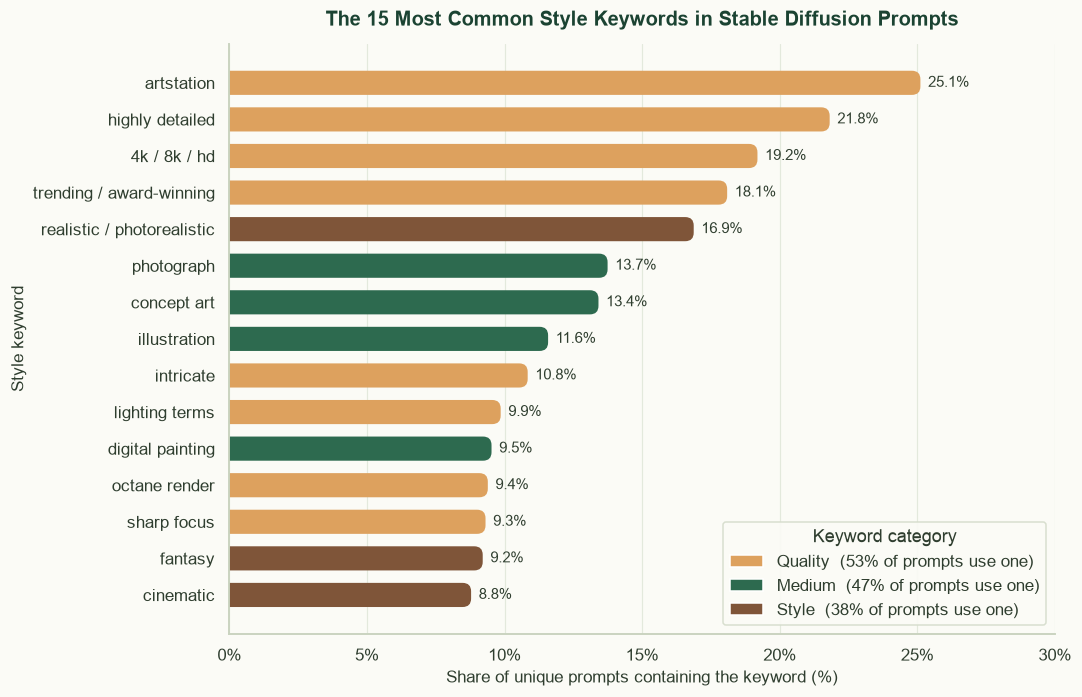

In [59]:
top_terms = term_share.head(15).iloc[::-1]               # reverse so the largest bar is on top
labels = top_terms.index.str.split(": ").str[1]
colors = top_terms["category"].map(CATEGORY_COLORS)

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(labels, top_terms["percent_of_prompts"], height=0.66, color=colors)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in top_terms["percent_of_prompts"]],
             padding=5, fontsize=9.5, color=INK)

category_share = category_use.mean() * 100                # from Section 5.2
legend_items = [Patch(facecolor=color, label=f"{cat.title()}  ({category_share[cat]:.0f}% of prompts use one)")
                for cat, color in CATEGORY_COLORS.items()]
ax.legend(handles=legend_items, title="Keyword category", loc="lower right")

ax.set_title("The 15 Most Common Style Keywords in Stable Diffusion Prompts")
ax.set_xlabel("Share of unique prompts containing the keyword (%)")
ax.set_ylabel("Style keyword")
ax.set_xlim(0, 30)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
plt.tight_layout()
round_bars(ax, radius=0.35, horizontal=True)
plt.show()

**What the chart shows:** the four longest bars are all *quality boosters* (gold): **artstation** (25.1%), **highly detailed** (21.8%), **4k / 8k / hd** (19.2%) and **trending / award-winning** (18.1%).
The first real art style, **realistic / photorealistic**, comes fifth (16.9%), and the most common mediums (photograph, concept art, illustration) follow at 11-14%.
The legend shows the same pattern at category level: 53% of prompts contain a quality booster, compared with 47% for a medium and 38% for an art style.

### 6.2 Visualization 2: Which artists are named, and how concentrated is their use? (Q1)

Two connected views:
* **(a) Bar chart** of the 10 most-named artists. The label also gives the number of *different users* who named the artist, and the color separates artists used across the community (named by at least 20% of users) from artists used by a small group.
* **(b) Cumulative line chart** (concentration curve): artists are sorted from most to least named, and the line shows what share of all artist mentions the top *k* artists account for. The x-axis uses a log scale so that both the few top names and the long tail of 2,816 names are visible.

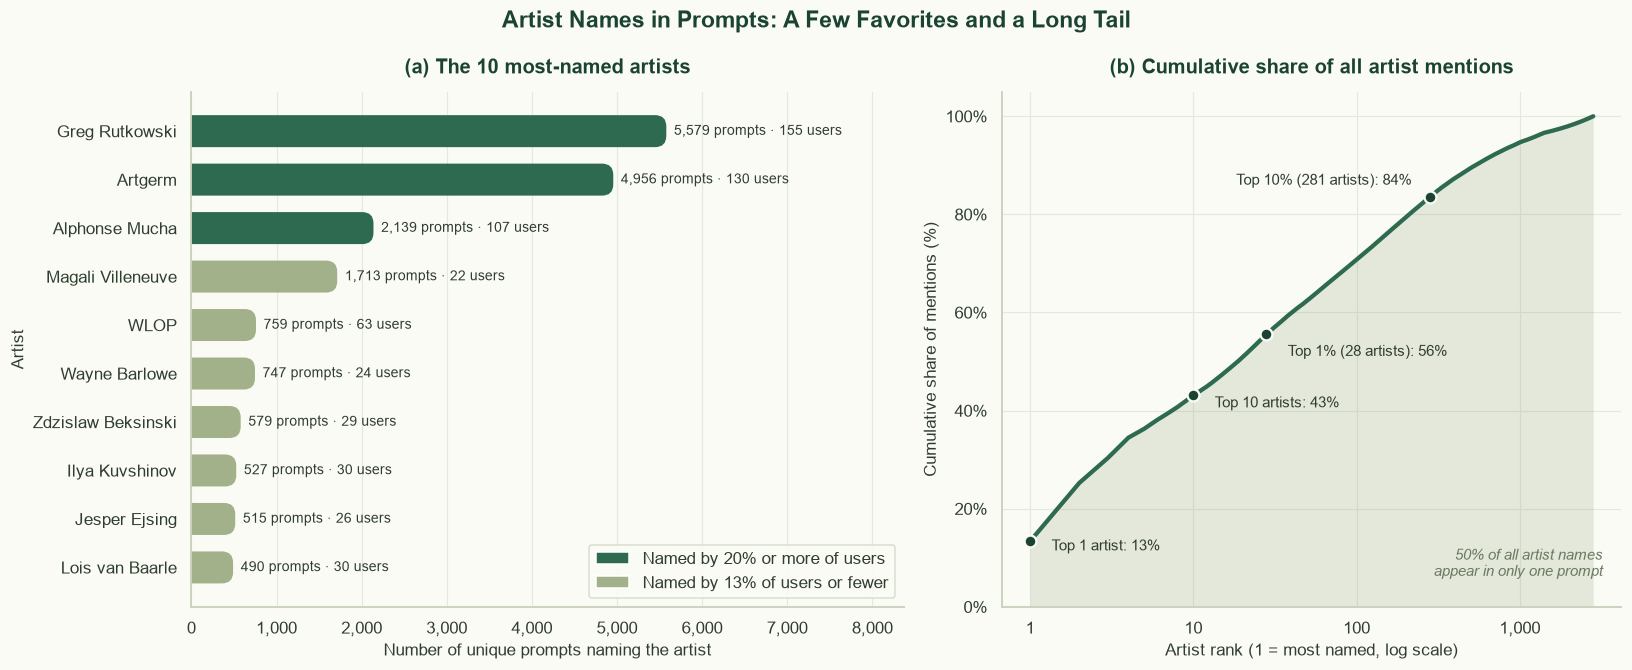

In [60]:
top10 = artist_users.sort_values("prompts")               # from Section 5.2, smallest first
names = top10.index.str.title().str.replace("Wlop", "WLOP").str.replace("Van Baarle", "van Baarle")
widely_used = top10["percent_of_users"] >= 20
colors = np.where(widely_used, FOREST["forest"], OTHER_COLOR)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})

# (a) Top 10 artists
bars = ax1.barh(names, top10["prompts"], height=0.66, color=colors)
ax1.bar_label(bars, labels=[f"{p:,} prompts · {u} users" for p, u in zip(top10["prompts"], top10["distinct_users"])],
              padding=5, fontsize=9, color=INK)
ax1.legend(handles=[Patch(facecolor=FOREST["forest"], label="Named by 20% or more of users"),
                    Patch(facecolor=OTHER_COLOR, label=f"Named by {top10.loc[~widely_used, 'percent_of_users'].max():.0f}% of users or fewer")],
           loc="lower right")
ax1.set_title("(a) The 10 most-named artists")
ax1.set_xlabel("Number of unique prompts naming the artist")
ax1.set_ylabel("Artist")
ax1.set_xlim(0, top10["prompts"].max() * 1.5)
ax1.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax1.grid(axis="y", visible=False)

# (b) Concentration curve
rank = np.arange(1, len(cum_share) + 1)
ax2.fill_between(rank, cum_share.values, color=FOREST["sage"], alpha=0.25, linewidth=0)
ax2.plot(rank, cum_share.values, color=FOREST["forest"], linewidth=2.8)
n_top1pct, n_top10pct = int(len(cum_share) * 0.01), int(len(cum_share) * 0.10)
marks = [(1, "Top 1 artist", (14, -6)), (10, "Top 10 artists", (14, -8)),
         (n_top1pct, f"Top 1% ({n_top1pct} artists)", (14, -14)),
         (n_top10pct, f"Top 10% ({n_top10pct} artists)", (-12, 8))]
for k, label, offset in marks:
    y = cum_share.iloc[k - 1]
    ax2.scatter(k, y, s=60, color=FOREST["pine"], edgecolor=BACKGROUND, linewidth=1.5, zorder=3)
    ax2.annotate(f"{label}: {y:.0f}%", (k, y), xytext=offset, textcoords="offset points",
                 ha="right" if offset[0] < 0 else "left", fontsize=9.5, color=INK)
single = (artist_counts == 1).mean()
ax2.text(0.97, 0.06, f"{single:.0%} of all artist names\nappear in only one prompt",
         transform=ax2.transAxes, ha="right", fontsize=9.5, color="#6b7a62", style="italic")
ax2.set_xscale("log")
ax2.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.set_title("(b) Cumulative share of all artist mentions")
ax2.set_xlabel("Artist rank (1 = most named, log scale)")
ax2.set_ylabel("Cumulative share of mentions (%)")

fig.suptitle("Artist Names in Prompts: A Few Favorites and a Long Tail", color=FOREST["pine"])
plt.tight_layout()
round_bars(ax1, radius=0.35, horizontal=True)
plt.show()

**What the chart shows:** **(a)** Greg Rutkowski (5,579 prompts) and Artgerm (4,956) are far ahead of every other artist. The three dark bars (Rutkowski, Artgerm, Mucha) are each named by 107-155 users, while names such as Magali Villeneuve (1,713 prompts, only 22 users) and Wayne Barlowe (24 users) reach the top 10 because a few users repeat them many times.
**(b)** The curve rises very steeply at the start: one artist accounts for 13% of all mentions, 10 artists for 43%, and the top 1% of names (28 artists) for 55%. After that it flattens into a long tail. Half of all names appear in only one prompt.

### 6.3 Visualization 3: How prompts change over the first five prompts of a session (Q2)

A **line chart** shows the change across an ordered sequence (1st to 5th prompt).
To compare the *same* sessions at every position, it uses the 3,867 sessions with at least 5 different prompts (`first5` from Section 5.3).
The shaded band is the **95% confidence interval** of the mean (mean ± 1.96 × standard error), which shows how precisely each average is estimated.
*Note:* the y-axes do not start at zero, so that the small change is visible. The real increase is about 2 words.

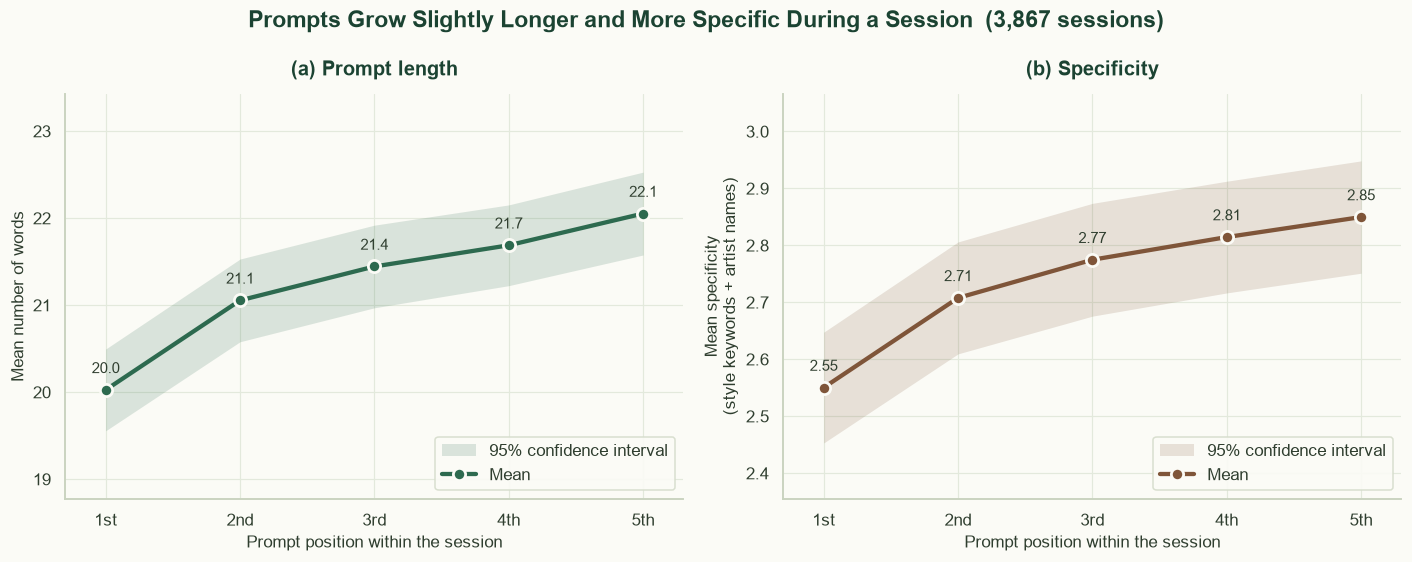

In [61]:
pos_stats = first5.groupby("position")[["prompt_words", "specificity"]].agg(["mean", "sem"])
n_sessions = first5["session_id"].nunique()

panels = [
    ("prompt_words", FOREST["forest"], "(a) Prompt length", "Mean number of words", "{:.1f}"),
    ("specificity", FOREST["bark"], "(b) Specificity", "Mean specificity\n(style keywords + artist names)", "{:.2f}"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (column, color, title, ylabel, fmt) in zip(axes, panels):
    mean = pos_stats[(column, "mean")]
    ci = 1.96 * pos_stats[(column, "sem")]
    ax.fill_between(mean.index, mean - ci, mean + ci, color=color, alpha=0.16, linewidth=0,
                    label="95% confidence interval")
    ax.plot(mean.index, mean, marker="o", linewidth=2.8, markersize=8, color=color,
            markeredgecolor=BACKGROUND, markeredgewidth=1.8, label="Mean")
    for x, y in mean.items():
        ax.annotate(fmt.format(y), (x, y), xytext=(0, 11), textcoords="offset points",
                    ha="center", fontsize=9.5, color=INK)
    ax.set_xticks(range(1, 6), ["1st", "2nd", "3rd", "4th", "5th"])
    ax.set_xlim(0.7, 5.3)
    ax.set_ylim((mean - ci).min() * 0.96, (mean + ci).max() * 1.04)
    ax.set_title(title)
    ax.set_xlabel("Prompt position within the session")
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower right")

fig.suptitle(f"Prompts Grow Slightly Longer and More Specific During a Session  ({n_sessions:,} sessions)",
             color=FOREST["pine"])
plt.tight_layout()
plt.show()

**What the chart shows:** both lines go up at every step. The mean prompt length rises from **20.0 to 22.1 words** and the mean specificity from **2.55 to 2.85** between the 1st and 5th prompt.
The largest step is from the 1st to the 2nd prompt (+1.0 word, +0.16 specificity). After that the lines keep rising but more slowly.
The confidence bands are narrow and the 1st and 5th positions do not overlap, so the increase is not just random noise. It is still small: about two words over five prompts.

### 6.4 Visualization 4: How much do prompts change, and how? (Q2)

* **(a) Histogram** of the change in length between the **first and the last prompt** of each session with at least 3 different prompts (`compare["word_change"]`, 5,033 sessions). Bars left of zero (brown) are sessions that ended with a *shorter* prompt, and bars right of zero (green) ended with a *longer* one. For readability the x-axis is limited to ±40 words, which covers about 99% of sessions.
* **(b) Stacked bar** that splits all 74,344 consecutive prompt changes (`pairs`) into *new ideas* (word overlap < 0.5) and *small edits*, which are further split by whether words were added, removed or swapped.

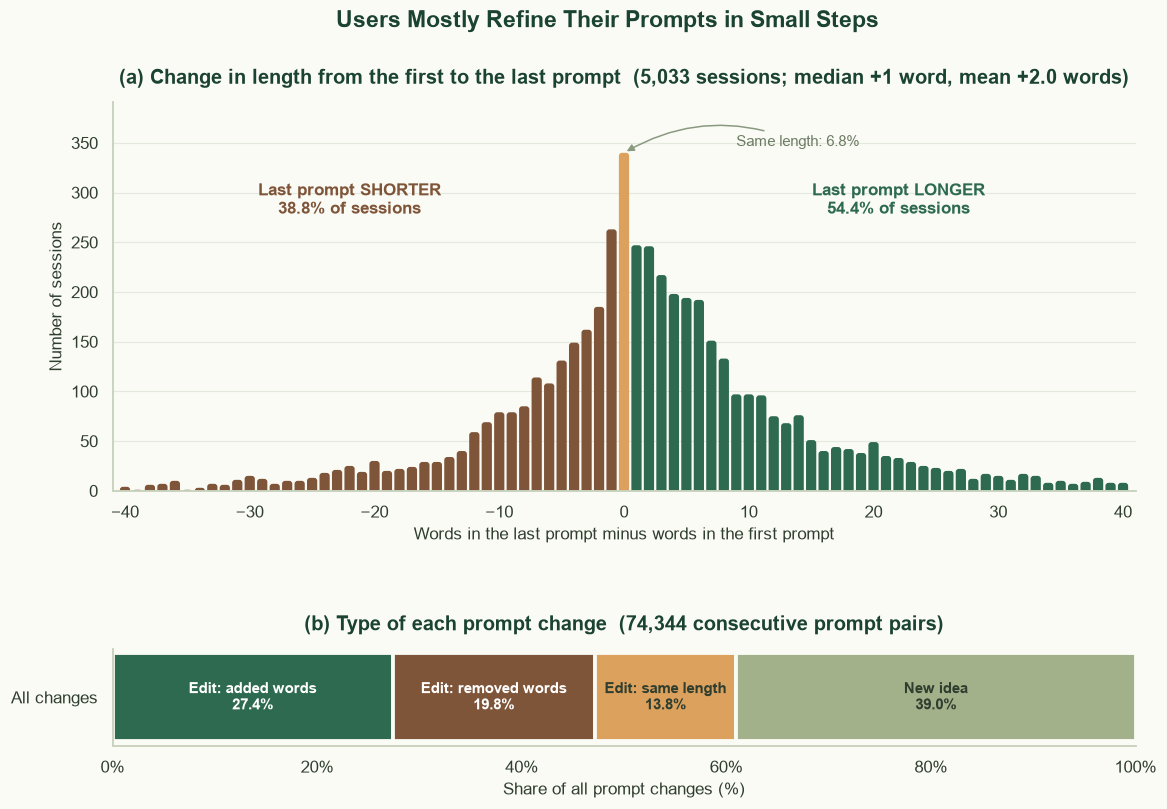

In [62]:
LIMIT = 40
change = compare["word_change"]
shown = change[change.between(-LIMIT, LIMIT)]

fig = plt.figure(figsize=(12, 7.6))
grid = fig.add_gridspec(2, 1, height_ratios=[4, 1], hspace=0.65)
ax = fig.add_subplot(grid[0])
ax_type = fig.add_subplot(grid[1])

# (a) Histogram with one bar per word of change
counts, edges, patches = ax.hist(shown, bins=np.arange(-LIMIT - 0.5, LIMIT + 1.5, 1), rwidth=0.82)
for patch, left in zip(patches, edges[:-1]):
    center = left + 0.5
    patch.set_facecolor(FOREST["bark"] if center < 0 else FOREST["forest"] if center > 0 else FOREST["lichen"])

shares = {"shorter": (change < 0).mean(), "same": (change == 0).mean(), "longer": (change > 0).mean()}
ax.text(-22, counts.max() * 0.82, f"Last prompt SHORTER\n{shares['shorter']:.1%} of sessions",
        ha="center", color=FOREST["bark"], fontsize=11, fontweight="bold")
ax.text(22, counts.max() * 0.82, f"Last prompt LONGER\n{shares['longer']:.1%} of sessions",
        ha="center", color=FOREST["forest"], fontsize=11, fontweight="bold")
ax.annotate(f"Same length: {shares['same']:.1%}", xy=(0, counts[LIMIT]), xytext=(9, counts.max() * 1.02),
            color="#6b7a62", fontsize=9.5,
            arrowprops=dict(arrowstyle="-|>", color="#8a9a80", connectionstyle="arc3,rad=0.25"))
ax.set_title(f"(a) Change in length from the first to the last prompt  ({len(change):,} sessions; "
             f"median {change.median():+.0f} word, mean {change.mean():+.1f} words)")
ax.set_xlabel("Words in the last prompt minus words in the first prompt")
ax.set_ylabel("Number of sessions")
ax.set_xlim(-LIMIT - 1, LIMIT + 1)
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)

# (b) Type of every consecutive prompt change
kind = np.where(pairs["revision_type"] == "new idea", "New idea", "Small edit: " + pairs["length_change"])
type_share = pd.Series(kind).value_counts(normalize=True).mul(100).reindex(
    ["Small edit: added words", "Small edit: removed words", "Small edit: same length", "New idea"])
type_colors = [FOREST["forest"], FOREST["bark"], FOREST["lichen"], OTHER_COLOR]
left = 0
for (label, value), color in zip(type_share.items(), type_colors):
    ax_type.barh(0, value, left=left, height=0.6, color=color, edgecolor=BACKGROUND, linewidth=2.5)
    ax_type.text(left + value / 2, 0, f"{label.replace('Small edit: ', 'Edit: ')}\n{value:.1f}%",
                 ha="center", va="center", fontsize=9.5, color=text_color_for(color), fontweight="bold")
    left += value
ax_type.set_xlim(0, 100)
ax_type.set_yticks([0], ["All changes"])
ax_type.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax_type.set_title(f"(b) Type of each prompt change  ({len(pairs):,} consecutive prompt pairs)")
ax_type.set_xlabel("Share of all prompt changes (%)")
ax_type.grid(visible=False)

fig.suptitle("Users Mostly Refine Their Prompts in Small Steps", color=FOREST["pine"], y=0.99)
round_bars(ax, radius=0.3)
plt.show()

**What the chart shows:** **(a)** the histogram is centered just above zero (median +1 word, mean +2.0 words) and is **wide**: most sessions change by fewer than 10 words, but many end 10-30 words longer and a smaller number end 10-30 words shorter. The right (longer) side holds more sessions and has the longer tail. Only 6.8% end with exactly the same length.
So "prompts get longer" is a tendency, not a rule: 54.4% of sessions end longer and 38.8% end shorter.
**(b)** 61% of all prompt changes are small edits of the same idea. The largest single group is edits that **add** a few words (27%). Edits that remove words (20%) and edits that swap words without changing the length (14%) are less common, and 39% of changes start a completely new idea.

### 6.5 Visualization 5: How are the generation settings distributed? (Q3)

Three **bar charts** side by side (small multiples) with the same y-axis, so the settings can be compared directly.
Each shows the most common values of one setting as a share of all generations (`df`). All remaining values are grouped as *other*.
The **dark bar is the default value** of the Stable Diffusion Discord bot (50 steps, guidance scale 7, 512 x 512 pixels).
The sampler is not shown because it is almost constant (`k_lms` in 98.4% of generations, see Section 5.4).

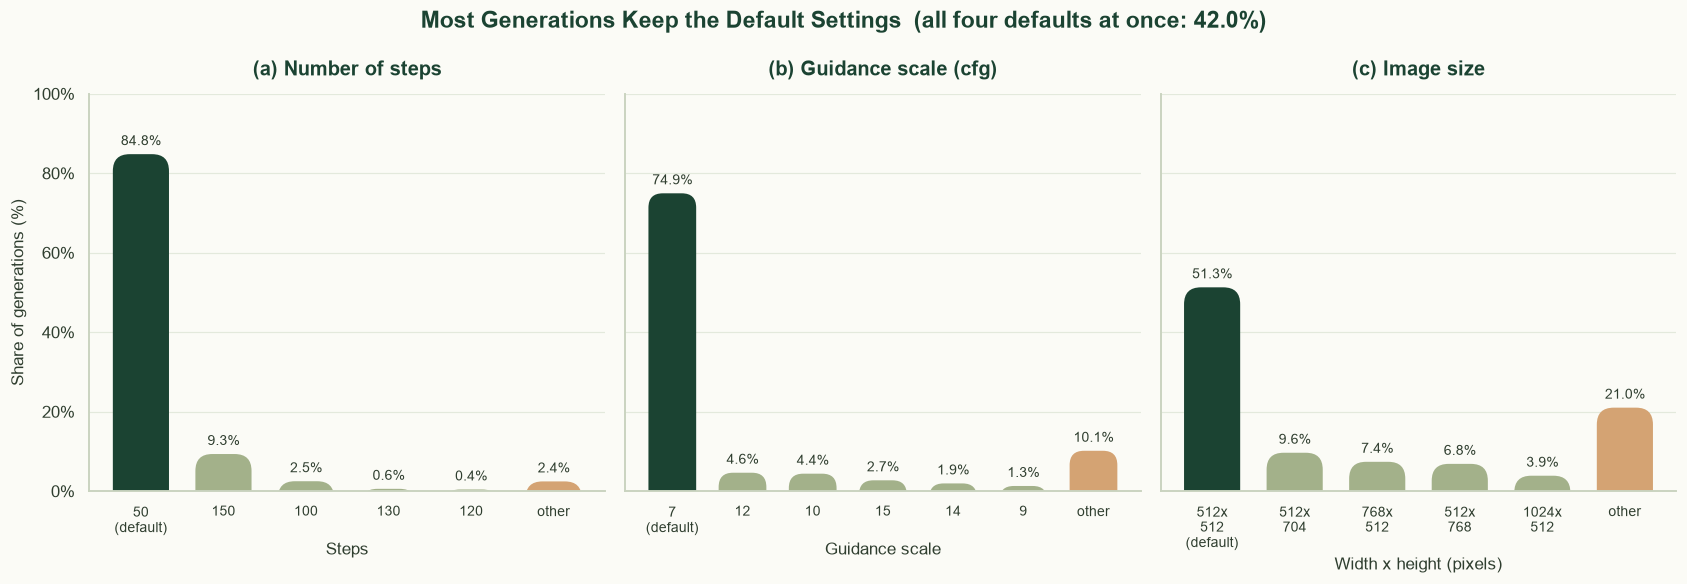

In [63]:
def share_with_other(column, n):
    # Share (%) of generations for the n most common values, plus one "other" bar for the rest
    shares = df[column].value_counts(normalize=True).mul(100)
    top = shares.head(n)
    return pd.concat([top, pd.Series({"other": 100 - top.sum()})])

panels = [
    ("step", 5, 50, "(a) Number of steps", "Steps", lambda v: f"{v:.0f}"),
    ("cfg", 6, 7, "(b) Guidance scale (cfg)", "Guidance scale", lambda v: f"{v:g}"),
    ("size", 5, "512x512", "(c) Image size", "Width x height (pixels)", lambda v: v.replace("x", "x\n")),
]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4), sharey=True)
for ax, (column, n, default, title, xlabel, fmt) in zip(axes, panels):
    shares = share_with_other(column, n)
    is_default = [value == default for value in shares.index]
    labels = [("other" if value == "other" else fmt(value)) + ("\n(default)" if d else "")
              for value, d in zip(shares.index, is_default)]
    colors = [DEFAULT_COLOR if d else FOREST["sand"] if value == "other" else OTHER_COLOR
              for value, d in zip(shares.index, is_default)]
    bars = ax.bar(labels, shares.values, width=0.68, color=colors)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in shares.values], padding=4, fontsize=9, color=INK)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=9)
axes[0].set_ylabel("Share of generations (%)")

fig.suptitle(f"Most Generations Keep the Default Settings  (all four defaults at once: {df['is_default'].mean():.1%})",
             color=FOREST["pine"])
plt.tight_layout()
for ax in axes:
    round_bars(ax, radius=0.3)
plt.show()

**What the chart shows:** the default bar is by far the tallest in every panel, but the settings are changed to very different degrees.
**Steps** stay at 50 in 84.8% of generations. When users change them, they jump to round values (150 = 9.3%, 100 = 2.5%).
The **guidance scale** stays at 7 in 74.9% of generations. The other values are spread over many numbers (12, 10, 15, 14, 9, ...), which is why the *other* bar is relatively tall (10.1%).
**Image size** is the setting changed most often: only 51.3% of images are 512 x 512, and the next sizes are portrait (512 x 704, 512 x 768) and landscape (768 x 512, 1024 x 512) formats, while 21% of images use one of many less common sizes.

### 6.6 Visualization 6: Do longer prompts go together with different settings? (Q3)

* **(a) Bar chart** of the share of generations that use **all four default settings**, for each prompt-length group (`settings_by_length` from Section 5.4). The number of generations in each group is shown under the label.
* **(b) Boxplot** of prompt length for each **guidance-scale group**. A boxplot compares whole distributions: the box covers the middle 50% of prompts, the white line is the median, and the whiskers extend to 1.5 × IQR. Outliers are hidden to keep the plot readable (Section 4.6 already discussed very long prompts).

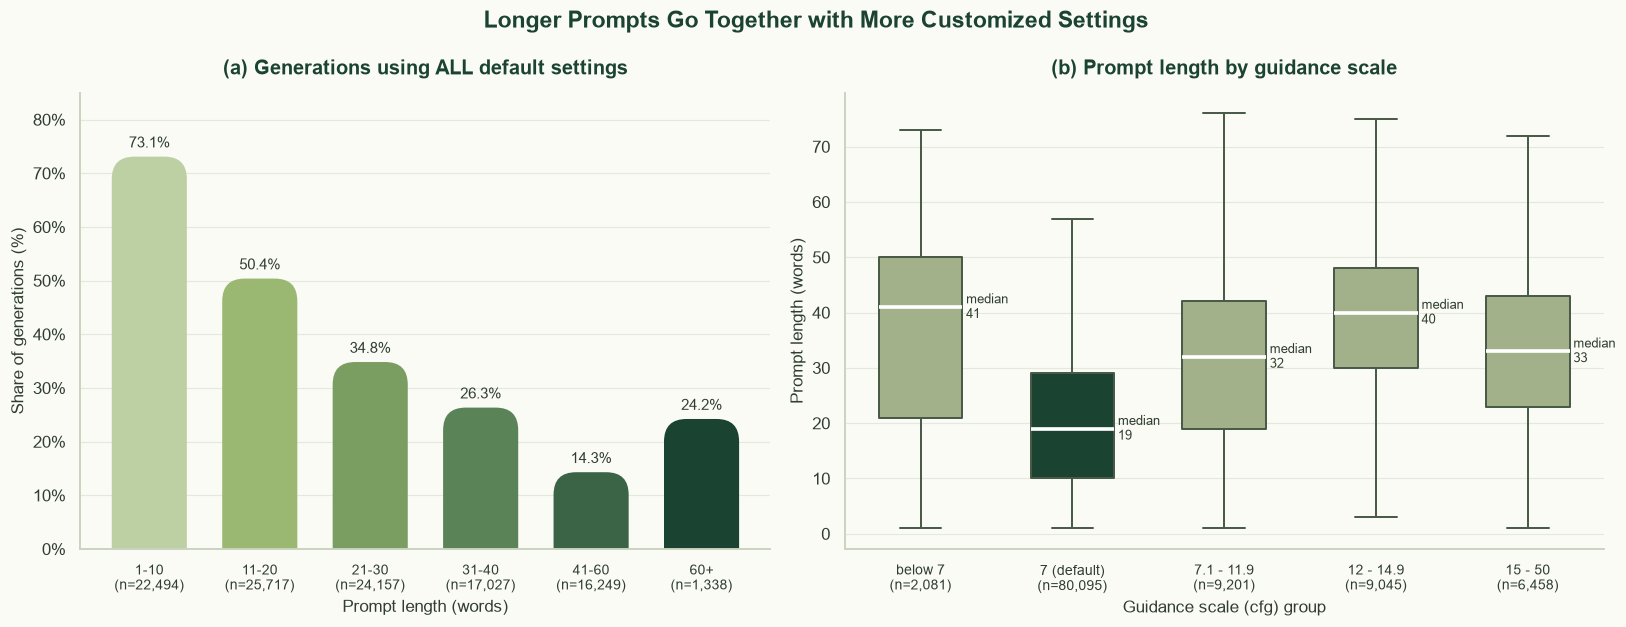

In [64]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.1]})

# (a) Share of all-default generations by prompt length
labels = [f"{group}\n(n={n:,})" for group, n in settings_by_length["generations"].items()]
colors = FOREST_CMAP(np.linspace(0.35, 1.0, len(labels)))     # darker = longer prompts
bars = ax1.bar(labels, settings_by_length["pct_default"], width=0.68, color=colors)
ax1.bar_label(bars, labels=[f"{v:.1f}%" for v in settings_by_length["pct_default"]],
              padding=4, fontsize=9.5, color=INK)
ax1.set_title("(a) Generations using ALL default settings")
ax1.set_xlabel("Prompt length (words)")
ax1.set_ylabel("Share of generations (%)")
ax1.set_ylim(0, 85)
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax1.grid(axis="x", visible=False)
ax1.tick_params(axis="x", labelsize=9)

# (b) Prompt length by guidance-scale group
cfg_groups = ["below 7", "7 (default)", "7.1 - 11.9", "12 - 14.9", "15 - 50"]
box_data = df.assign(cfg_group=pd.cut(df["cfg"], bins=[-0.1, 6.999, 7, 11.999, 14.999, 50], labels=cfg_groups))
group_sizes = box_data["cfg_group"].value_counts()
box_colors = {g: DEFAULT_COLOR if g == "7 (default)" else OTHER_COLOR for g in cfg_groups}

sns.boxplot(data=box_data, x="cfg_group", y="prompt_words", hue="cfg_group", order=cfg_groups,
            palette=box_colors, legend=False, dodge=False, width=0.55, saturation=1, showfliers=False,
            linecolor="#4a5a48", linewidth=1.3, medianprops=dict(color="white", linewidth=2.4), ax=ax2)
for patch in ax2.patches:          # soften box corners
    patch.set_joinstyle("round")
for i, group in enumerate(cfg_groups):
    median = box_data.loc[box_data["cfg_group"] == group, "prompt_words"].median()
    ax2.annotate(f"median\n{median:.0f}", (i + 0.3, median), ha="left", va="center",
                 fontsize=8.5, color=INK)
ax2.set_xticks(range(len(cfg_groups)), [f"{g}\n(n={group_sizes[g]:,})" for g in cfg_groups], fontsize=9)
ax2.set_title("(b) Prompt length by guidance scale")
ax2.set_xlabel("Guidance scale (cfg) group")
ax2.set_ylabel("Prompt length (words)")

fig.suptitle("Longer Prompts Go Together with More Customized Settings", color=FOREST["pine"])
plt.tight_layout()
round_bars(ax1, radius=0.3)
plt.show()

**What the chart shows:** **(a)** the share of all-default generations falls steadily from **73.1%** for prompts of 1-10 words to **14.3%** for 41-60 words. The small 60+ group (1,338 generations) is the only exception, at 24.2%.
**(b)** generations with the default guidance scale (dark box) have the shortest prompts (median 19 words). Every non-default group has a much higher median (32-41 words), and most of the default box (10-29 words) lies below those medians.
Interestingly, users who *lower* the guidance scale below 7 also write long prompts (median 41). So long prompts go together with *changing* the setting, not only with *raising* it.

### 6.7 Visualization 7: Correlations between prompt features and settings (Q3)

A **heatmap** of the Spearman correlation matrix from Section 5.4 (`corr`).
We use **Spearman** (rank-based) correlation because the settings are very skewed (most values are exactly the default), and a rank correlation is not distorted by extreme values.
Only the lower triangle is shown because the matrix is symmetric. Darker green = stronger positive correlation. All correlations are positive.

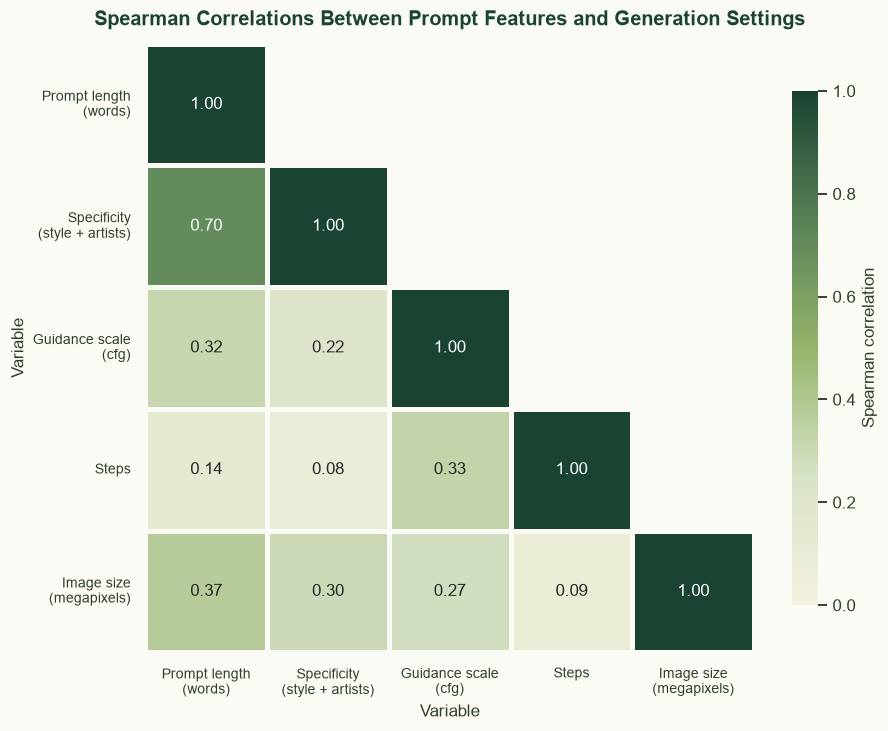

In [65]:
readable = {
    "prompt_words": "Prompt length\n(words)",
    "specificity": "Specificity\n(style + artists)",
    "cfg": "Guidance scale\n(cfg)",
    "step": "Steps",
    "megapixels": "Image size\n(megapixels)",
}
corr_named = corr.rename(index=readable, columns=readable)
mask = np.triu(np.ones_like(corr_named, dtype=bool), k=1)      # hide the upper triangle

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr_named, mask=mask, cmap=FOREST_CMAP, vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 11}, linewidths=3, linecolor=BACKGROUND, square=True,
            cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Spearman Correlations Between Prompt Features and Generation Settings")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
ax.grid(False)
plt.tight_layout()
plt.show()

**What the chart shows:** the darkest cell is **prompt length vs. specificity (0.70)**. This is expected, because adding style keywords and artist names makes a prompt longer.
Between prompt features and settings, the correlations are **weak to moderate**: prompt length correlates 0.37 with image size, 0.32 with guidance scale and only 0.14 with steps. Specificity shows the same pattern but slightly weaker (0.30, 0.22, 0.08).
The settings are also related to each other (guidance scale vs. steps 0.33, guidance scale vs. image size 0.27). Users who change one setting tend to change others too.

## Section 7 - Interpretation of Results

Here we explain what the results of Sections 5 and 6 mean, one research question at a time, and what they do **not** allow us to conclude.
Before interpreting Q2 and Q3 we run three short checks, because two of our earlier explanations needed more evidence:
1. Does the link between long prompts and customized settings also hold **within the same user**, or only **between** different users?
2. How much of each prompt-length group comes from the **10% most active users**?
3. How reliable is the **order** of prompts inside a session, given that timestamps are rounded to the minute?

In [66]:
# 1) Within-user check: for every real user with at least 50 generations, the Spearman correlation
#    between prompt length and using all default settings (Pearson correlation of the ranks = Spearman).
active = df[df["is_real_user"]].groupby("user_name").filter(lambda g: len(g) >= 50)
within_user = (
    active.groupby("user_name")
          .apply(lambda g: g["prompt_words"].rank().corr(g["is_default"].astype(float).rank()))
          .dropna()                     # users who always (or never) use the defaults have no correlation
)
print(f"Users with >= 50 generations and some variation in settings: {len(within_user)}")
print(f"Median within-user correlation (prompt length vs. all defaults): {within_user.median():.2f}")
print(f"Users with a NEGATIVE correlation (longer prompt -> fewer defaults): {(within_user < 0).mean():.1%}")

# 2) Share of each prompt-length group produced by the 10% most active users (per_user is sorted in 5.1)
heavy_users = per_user.head(int(len(per_user) * 0.10)).index
heavy_share = (
    df.assign(heavy_user=df["user_name"].isin(heavy_users))
      .groupby("length_group", observed=True)["heavy_user"].mean()
      .mul(100).round(1)
      .rename("percent_from_top_10pct_users")
)
print()
print(heavy_share)

# 3) Consecutive prompt changes whose two prompts have the same timestamp (same minute)
prev_time = seq.groupby("session_id")["timestamp"].shift()
same_minute = (pairs["timestamp"] == prev_time.loc[pairs.index]).mean()
print(f"\nPrompt changes where both prompts are in the same minute (order uncertain): {same_minute:.1%}")

Users with >= 50 generations and some variation in settings: 247
Median within-user correlation (prompt length vs. all defaults): -0.22
Users with a NEGATIVE correlation (longer prompt -> fewer defaults): 88.3%

length_group
1-10    32.600
11-20   39.200
21-30   63.000
31-40   62.900
41-60   71.900
60+     53.100
Name: percent_from_top_10pct_users, dtype: float64

Prompt changes where both prompts are in the same minute (order uncertain): 6.7%


### 7.1 Q1 - Prompts follow a shared "recipe" more than a personal style

* **Quality boosters beat art styles.** Visualization 1 shows that the most common words in prompts are not styles or mediums but generic quality phrases (*artstation*, *highly detailed*, *4k*, *trending on*). These words do not describe what the image should look like stylistically. They are general instructions to make it "good".
  We interpret this as evidence of a **shared prompting recipe**: in August 2022, users on the public Discord server could see each other's prompts and results, and phrases that seemed to work spread quickly. Our data shows the pattern, but it cannot prove *why* users copied it.
* **Artist names follow a "winner-takes-most" pattern.** Visualization 2 shows a very steep concentration curve: 10 names make up 43% of all mentions, while half of the 2,816 names appear only once. Most of these artists are **digital fantasy illustrators** (Rutkowski, Artgerm, WLOP, Magali Villeneuve), plus Alphonse Mucha, whose Art Nouveau style is easy to recognize. This fits the quality-booster pattern: users seem to name artists as a quick shortcut to a polished, "ArtStation-like" look.
* **Prompt counts can overstate popularity.** Panel 2a shows that only the top three artists are named by a large part of the community (21-31% of users). Magali Villeneuve has the 4th-highest number of prompts but is used by only 22 users (4.4%). Because a few heavy users write many prompts (Section 5.1), **the number of distinct users is a more reliable measure of popularity** than the raw number of mentions.
* **Caution:** keyword shares depend on our dictionary of 38 terms and on our artist extraction (names after "by"). Styles or artists described in other words are missing, so the true shares are probably somewhat higher. The **ranking** of the most common terms is more reliable than the exact percentages.

### 7.2 Q2 - Users refine their prompts step by step rather than starting over

* **Growth is real but small.** Visualization 3 shows prompts becoming longer (+2.0 words) and slightly more specific (+0.3) over the first five prompts. The confidence bands show that this is not random noise. In practical terms, however, users add about **one short phrase**, not a new paragraph.
* **The average hides two opposite behaviors.** The histogram in Visualization 4 is wide on *both* sides of zero: 54% of sessions end with a longer prompt, but 39% end with a shorter one. Some users build up their prompts, while others trim them, for example after finding that a long list of keywords did not help. A single "prompts get longer" statement would therefore be misleading.
* **Edits target the subject, not the style.** 61% of prompt changes are small edits, and Section 5.3 showed that 82% of these edits keep the same number of style keywords and artists. Together with Q1, this suggests a typical workflow: users **settle on a style recipe early** and then adjust the content (the subject, details, composition) while keeping the recipe fixed.
* **How reliable is the order?** The check above shows that in about **6.7%** of prompt changes both prompts have the same timestamp (the data is rounded to the minute), so their real order is unknown. This affects only a small share of pairs and cannot create the steady trend seen in Visualization 3. The exact percentages may still shift slightly.
* **Caution:** the results depend on our own definitions: a 30-minute gap starts a new session, and a word overlap of 0.5 separates a "small edit" from a "new idea". Other reasonable thresholds would change the exact numbers, though probably not the overall direction.

### 7.3 Q3 - Defaults dominate, and customization goes together with longer prompts

* **Defaults dominate, but not equally.** Visualization 5 shows that the setting users change most is **image size** (about half of all generations). Steps and guidance scale are changed much less often, and the sampler almost never. A plausible reason is that image size has a **visible and easy-to-understand effect** (portrait vs. landscape), while steps and guidance scale require more technical knowledge. This is our interpretation and is not tested directly.
* **Longer prompts go together with customized settings.** Visualization 6 shows a strong gradient: 73% of short prompts use all defaults, compared with 14% of long ones, and default-cfg prompts are clearly shorter than prompts with any other cfg. Visualization 7 puts a number on this: the correlations are positive but only **weak to moderate (0.14-0.37)**, so prompt length explains only part of how people choose their settings.
* **Who is behind the pattern?** The first check above shows that the relationship also holds **within users**: for most active users (88% of them) longer prompts go together with fewer default settings, with a median correlation of about -0.22. So it is not only that "expert users write long prompts and change settings". **The same person also tends to customize more when they write a longer prompt.** At the same time, the second check shows that the 10% most active users produce about **72%** of the generations in the 41-60-word group but only **33%** in the 1-10-word group. So the long-prompt groups mostly reflect the habits of a relatively small number of very active users.
* **Association, not causation.** None of these results show that a long prompt *causes* a user to change settings, or the other way around. A likely common factor is **engagement**: when users care more about a particular image, they invest more effort in *both* the text and the settings. Our data does not measure engagement or experience directly, so this explanation remains a hypothesis.

### 7.4 Overall picture

The three questions point to one consistent pattern. **Most users follow shared conventions:** a common recipe of quality boosters, a handful of famous artists and the default settings.
A **smaller group of very active users** writes longer, more specific prompts, refines them over many generations and adjusts the settings much more. Because this group produces about half of all generations (Section 5.1), it has a large influence on any simple count.
For this reason we report results per unique prompt and, where possible, per user, and we read every percentage as a description of **this community of early Stable Diffusion users in August 2022**, not of AI image generation users in general.

## Section 8 - Answers to the Research Questions

_To be completed._

## Section 9 - Limitations

_To be completed._

## Section 10 - Conclusion

_To be completed._

## Section 11 - References

1. Wang, Z. J., Montoya, E., Munechika, D., Yang, H., Hoover, B., & Chau, D. H. (2022). *DiffusionDB: A Large-scale Prompt Gallery Dataset for Text-to-Image Generative Models.* arXiv:2210.14896. https://arxiv.org/abs/2210.14896
2. DiffusionDB dataset on Hugging Face: https://huggingface.co/datasets/poloclub/diffusiondb
3. DiffusionDB GitHub repository and documentation: https://github.com/poloclub/diffusiondb
4. pandas documentation: https://pandas.pydata.org/docs/
5. Matplotlib documentation: https://matplotlib.org/stable/
6. seaborn documentation: https://seaborn.pydata.org/
7. Matplotlib `FancyBboxPatch` (used for the rounded bar ends in Section 6): https://matplotlib.org/stable/api/_as_gen/matplotlib.patches.FancyBboxPatch.html
8. seaborn `boxplot` and `heatmap` documentation: https://seaborn.pydata.org/generated/seaborn.boxplot.html, https://seaborn.pydata.org/generated/seaborn.heatmap.html
9. Spearman rank correlation in pandas (`DataFrame.corr`): https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html